# AI-Powered Automated Underwater Marine Debris and Anomaly Detection System Using Side-Scan Sonar Imagery

## Project Overview

This case study investigates deep-learning methods for identifying annotated underwater objects in side-scan sonar imagery. The current dataset is **SSS-Marine-Debris-Detection**, exported in YOLOv8 object-detection format.

Two complementary approaches are implemented: a custom Convolutional Neural Network (CNN) classifies square crops extracted from annotated objects, while YOLOv8n predicts object classes and bounding boxes in full sonar images.

An additional **image-level target-presence screening experiment** uses YOLOv8n predictions to flag images containing at least one detected target. This is a limited, dataset-defined anomaly-screening proxy: it detects the three known annotated classes and does not claim to detect previously unseen anomaly types.

## Dataset

The SSS-Marine-Debris-Detection dataset contains three annotated categories:

1. Fishing Gear or Crab Pot
2. Pipelines or Cylinders
3. ShipWrecks

The dataset has training, validation, and test splits with YOLO-format bounding-box annotations. The notebook validates the files and annotations and creates a recording-group-aware split. Residual perceptual-hash candidates are documented as a limitation; group-aware splitting reduces one leakage risk but does not prove that every related frame is independent.

## Objectives

- Validate images and YOLO annotations and examine class distributions.
- Investigate duplicate images and reduce recording-related split leakage.
- Develop a CNN classification baseline using annotated object crops and evaluate it on validation and test crops.
- Train YOLOv8n to detect and localize the three annotated object classes.
- Evaluate detection metrics on the held-out test split.
- Measure image-level target-presence screening performance, including false alarms on empty-label images.
- Analyze errors and document limitations.

## Methodology

Dataset validation → Exploratory Data Analysis → Leakage Checks → Group-Aware Splitting → CNN Crop Classification → YOLOv8n Detection → Object-Level and Image-Level Evaluation → Conclusion.


## Phase 0: Notebook Setup and Reproducibility

This phase establishes the computational environment for the case study. It imports the common libraries, sets random seeds to improve reproducibility, and records the Python, PyTorch, and available hardware configuration. These initial checks help document the environment used in subsequent experiments.

In [ ]:
import os
import sys
import random
import platform
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Basic libraries imported successfully.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy version: 2.1.3
Pandas version: 2.2.3
Basic libraries imported successfully.


In [ ]:
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. In Colab, select Runtime > Change runtime type > T4 GPU.")

PyTorch version: 2.11.0+cpu
CUDA available: False
GPU not detected. In Colab, select Runtime > Change runtime type > T4 GPU.


## Phase 1: Environment Setup and Dataset Configuration

This phase mounts Google Drive, defines the project and dataset paths, and inspects the dataset directory structure and original YAML configuration. It establishes the class names and creates a corrected dataset configuration with explicit train, validation, and test paths. These checks prepare the dataset for systematic validation.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/dl case study")

DATASET_ROOT = (
    PROJECT_DIR
    / "datasets"
    / "SSS-Marine-Debris-Detection.v2i.yolov8"
)

OUTPUT_DIR = PROJECT_DIR / "validation_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset exists:", DATASET_ROOT.is_dir())
print("Dataset path:", DATASET_ROOT)
print("Output directory:", OUTPUT_DIR)

Dataset exists: True
Dataset path: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.v2i.yolov8
Output directory: /content/drive/MyDrive/dl case study/validation_outputs


In [ ]:
for item in sorted(DATASET_ROOT.iterdir()):
    print("[DIR] " if item.is_dir() else "[FILE]", item.name)

[FILE] README.dataset.txt
[FILE] README.roboflow.txt
[FILE] data (2).yaml
[FILE] data (3).yaml
[FILE] data.yaml
[DIR]  test
[DIR]  train
[DIR]  valid


In [ ]:
for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")

    for subfolder in ["images", "labels"]:
        folder = DATASET_ROOT / split / subfolder
        print(f"{subfolder}: exists={folder.is_dir()}")

        if folder.is_dir():
            print("  Files:", len(list(folder.iterdir())))


TRAIN
images: exists=True
  Files: 921
labels: exists=True
  Files: 921

VALID
images: exists=True
  Files: 263
labels: exists=True
  Files: 263

TEST
images: exists=True
  Files: 131
labels: exists=True
  Files: 131


In [ ]:
import yaml

for yaml_file in sorted(DATASET_ROOT.glob("*.yaml")):
    print(f"\n--- {yaml_file.name} ---")

    with open(yaml_file, "r") as file:
        config = yaml.safe_load(file)

    print(config)


--- data (2).yaml ---
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks'], 'roboflow': {'workspace': 'shaik-riyaz-baerg', 'project': 'sss-marine-debris-detection', 'version': 2, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/shaik-riyaz-baerg/sss-marine-debris-detection/dataset/2'}}

--- data (3).yaml ---
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks'], 'roboflow': {'workspace': 'shaik-riyaz-baerg', 'project': 'sss-marine-debris-detection', 'version': 2, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/shaik-riyaz-baerg/sss-marine-debris-detection/dataset/2'}}

--- data.yaml ---
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['Fishing Gear or Crab Pot', 'Pipelines or Cylinde

In [ ]:
CLASS_NAMES = [
    "Fishing Gear or Crab Pot",
    "Pipelines or Cylinders",
    "ShipWrecks",
]

FIXED_YAML = OUTPUT_DIR / "sss_marine_debris_data.yaml"

corrected_config = {
    "path": str(DATASET_ROOT),
    "train": str(DATASET_ROOT / "train" / "images"),
    "val": str(DATASET_ROOT / "valid" / "images"),
    "test": str(DATASET_ROOT / "test" / "images"),
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}

with open(FIXED_YAML, "w") as file:
    yaml.safe_dump(corrected_config, file, sort_keys=False)

print(FIXED_YAML.read_text())

path: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.v2i.yolov8
train: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.v2i.yolov8/train/images
val: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.v2i.yolov8/valid/images
test: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.v2i.yolov8/test/images
nc: 3
names:
- Fishing Gear or Crab Pot
- Pipelines or Cylinders
- ShipWrecks



In [ ]:
for split in ["train", "valid", "test"]:
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    assert image_dir.is_dir(), f"Missing: {image_dir}"
    assert label_dir.is_dir(), f"Missing: {label_dir}"

assert len(CLASS_NAMES) == 3

print("Folder structure verified.")
print("Class names:", CLASS_NAMES)
print("Training YAML:", FIXED_YAML)

Folder structure verified.
Class names: ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks']
Training YAML: /content/drive/MyDrive/dl case study/validation_outputs/sss_marine_debris_data.yaml


## Phase 2: Dataset Validation and Annotation Integrity

This phase checks the integrity of the side-scan sonar dataset before analysis and training. It verifies image-label pairing, identifies unreadable images, validates YOLO annotation formats and class IDs, and records empty-label images. Empty labels are treated as valid negative examples when they represent images without annotated objects. The purpose is to identify data-quality issues before model development.

In [ ]:
# PHASE 2 - CELL 11: IMPORT IMAGE VALIDATION TOOLS

from PIL import Image, UnidentifiedImageError

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Image validation tools ready.")

Image validation tools ready.


In [ ]:
pairing_issues = []
unreadable_images = []
image_counts = {}

for split in ["train", "valid", "test"]:
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_counts[split] = len(images)

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.is_file():
            pairing_issues.append(
                (split, image_path.name, "Missing label file")
            )

        try:
            with Image.open(image_path) as img:
                img.verify()
        except (OSError, UnidentifiedImageError):
            unreadable_images.append((split, image_path.name))

    for label_path in label_dir.glob("*.txt"):
        matching_image = any(
            (image_dir / f"{label_path.stem}{ext}").is_file()
            for ext in IMAGE_EXTENSIONS
        )

        if not matching_image:
            pairing_issues.append(
                (split, label_path.name, "Label without matching image")
            )

print("Image counts:", image_counts)
print("Pairing issues:", len(pairing_issues))
print("Unreadable images:", len(unreadable_images))

if pairing_issues:
    display(pd.DataFrame(
        pairing_issues,
        columns=["split", "file", "issue"]
    ).head(20))

if unreadable_images:
    display(pd.DataFrame(
        unreadable_images,
        columns=["split", "file"]
    ).head(20))

Image counts: {'train': 921, 'valid': 263, 'test': 131}
Pairing issues: 0
Unreadable images: 0


In [ ]:
annotation_issues = []
class_counts = Counter()
empty_label_files = []

for split in ["train", "valid", "test"]:
    label_dir = DATASET_ROOT / split / "labels"

    for label_path in label_dir.glob("*.txt"):
        lines = label_path.read_text().splitlines()

        if not lines:
            empty_label_files.append((split, label_path.name))
            continue

        for line_number, line in enumerate(lines, start=1):
            parts = line.split()

            if len(parts) != 5:
                annotation_issues.append(
                    (split, label_path.name, line_number,
                     "Expected 5 values")
                )
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])
            except ValueError:
                annotation_issues.append(
                    (split, label_path.name, line_number,
                     "Invalid numeric value")
                )
                continue

            if not 0 <= class_id < len(CLASS_NAMES):
                annotation_issues.append(
                    (split, label_path.name, line_number,
                     f"Invalid class ID: {class_id}")
                )
                continue

            if not np.all(np.isfinite([x, y, w, h])):
                annotation_issues.append(
                    (split, label_path.name, line_number,
                     "Non-finite coordinates")
                )
                continue

            if not (
                0 <= x <= 1 and 0 <= y <= 1
                and 0 < w <= 1 and 0 < h <= 1
                and x - w / 2 >= -1e-6
                and y - h / 2 >= -1e-6
                and x + w / 2 <= 1 + 1e-6
                and y + h / 2 <= 1 + 1e-6
            ):
                annotation_issues.append(
                    (split, label_path.name, line_number,
                     "Invalid or out-of-bounds bounding box")
                )
                continue

            class_counts[(split, class_id)] += 1

print("Invalid annotation rows:", len(annotation_issues))
print("Empty label files:", len(empty_label_files))

if annotation_issues:
    display(pd.DataFrame(
        annotation_issues,
        columns=["split", "file", "line", "issue"]
    ).head(30))
else:
    print("All parsed annotations passed these checks.")

Invalid annotation rows: 0
Empty label files: 162
All parsed annotations passed these checks.


## Phase 3: Exploratory Data Analysis

This phase examines the dataset's composition and visual characteristics. It summarizes annotated object counts by class and split, explores image dimensions and image modes, and visualizes representative images with their bounding boxes. It also inspects empty-label images to better understand the dataset's background examples and class distribution.

In [ ]:
class_summary = []

for split in ["train", "valid", "test"]:
    for class_id, class_name in enumerate(CLASS_NAMES):
        class_summary.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_name,
            "object_count": class_counts[(split, class_id)]
        })

class_df = pd.DataFrame(class_summary)
display(class_df)

,split,class_id,class_name,object_count
0,train,0,Fishing Gear or Crab Pot,620
1,train,1,Pipelines or Cylinders,321
2,train,2,ShipWrecks,188
3,valid,0,Fishing Gear or Crab Pot,183
4,valid,1,Pipelines or Cylinders,101
5,valid,2,ShipWrecks,38
6,test,0,Fishing Gear or Crab Pot,119
7,test,1,Pipelines or Cylinders,35
8,test,2,ShipWrecks,27


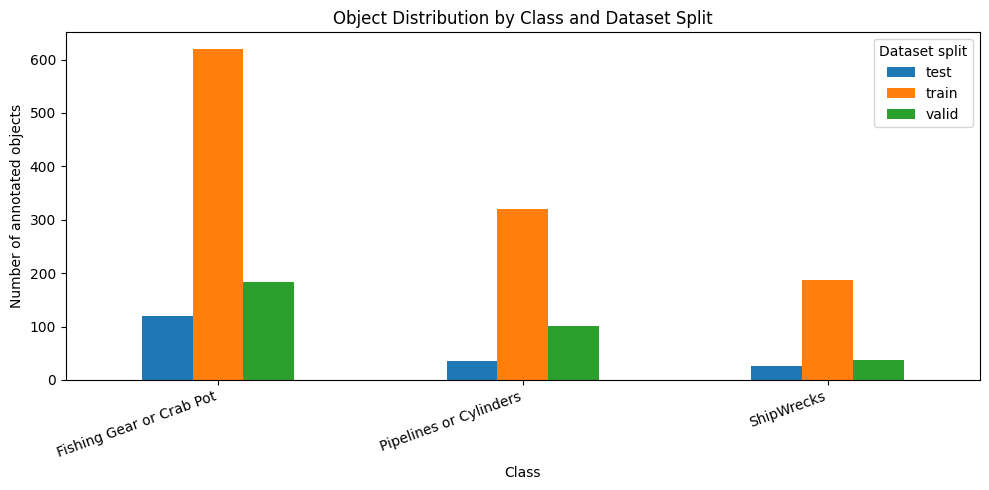

In [ ]:
class_pivot = class_df.pivot(
    index="class_name",
    columns="split",
    values="object_count"
).fillna(0)

class_pivot.plot(kind="bar", figsize=(10, 5))

plt.title("Object Distribution by Class and Dataset Split")
plt.xlabel("Class")
plt.ylabel("Number of annotated objects")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Dataset split")
plt.tight_layout()
plt.show()

In [ ]:
dimension_records = []

for split in ["train", "valid", "test"]:
    image_dir = DATASET_ROOT / split / "images"

    for image_path in image_dir.iterdir():
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(image_path) as img:
                width, height = img.size

            dimension_records.append({
                "split": split,
                "filename": image_path.name,
                "width": width,
                "height": height,
                "mode": img.mode
            })
        except (OSError, UnidentifiedImageError):
            pass

dimensions_df = pd.DataFrame(dimension_records)

print("Readable images inspected:", len(dimensions_df))
display(dimensions_df.groupby("split")[["width", "height"]].describe())
print("\nImage modes:")
print(dimensions_df["mode"].value_counts())

Readable images inspected: 1315


width                                                height         \
       count   mean  std    min    25%    50%    75%    max  count   mean   
split                                                                       
test   131.0  640.0  0.0  640.0  640.0  640.0  640.0  640.0  131.0  640.0   
train  921.0  640.0  0.0  640.0  640.0  640.0  640.0  640.0  921.0  640.0   
valid  263.0  640.0  0.0  640.0  640.0  640.0  640.0  640.0  263.0  640.0   

                                               
       std    min    25%    50%    75%    max  
split                                          
test   0.0  640.0  640.0  640.0  640.0  640.0  
train  0.0  640.0  640.0  640.0  640.0  640.0  
valid  0.0  640.0  640.0  640.0  640.0  640.0


Image modes:
mode
RGB    1315
Name: count, dtype: int64


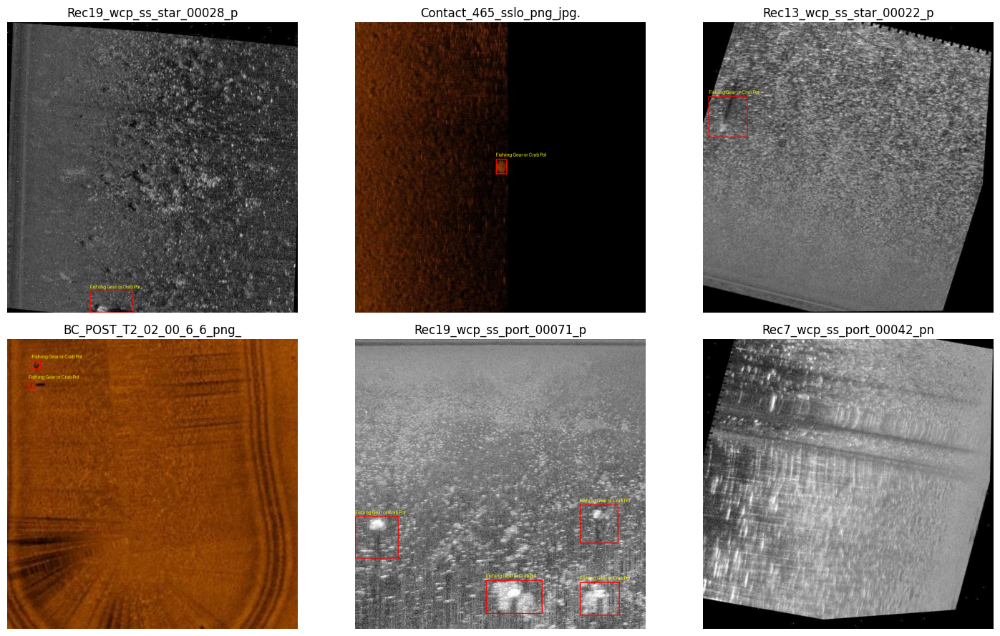

In [ ]:
import random
from PIL import ImageDraw

def show_annotated_samples(split="train", samples=6):
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    image_paths = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    selected = random.sample(image_paths, min(samples, len(image_paths)))

    fig, axes = plt.subplots(
        2, 3, figsize=(15, 9)
    )
    axes = axes.flatten()

    for ax, image_path in zip(axes, selected):
        with Image.open(image_path) as source:
            img = source.convert("RGB")

        draw = ImageDraw.Draw(img)
        label_path = label_dir / f"{image_path.stem}.txt"

        if label_path.exists():
            for line in label_path.read_text().splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue

                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                left = (x - w / 2) * img.width
                top = (y - h / 2) * img.height
                right = (x + w / 2) * img.width
                bottom = (y + h / 2) * img.height

                draw.rectangle(
                    [left, top, right, bottom],
                    outline="red",
                    width=2
                )
                draw.text(
                    (left, max(0, top - 15)),
                    CLASS_NAMES[class_id],
                    fill="yellow"
                )

        ax.imshow(img)
        ax.set_title(image_path.name[:25])
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_annotated_samples()

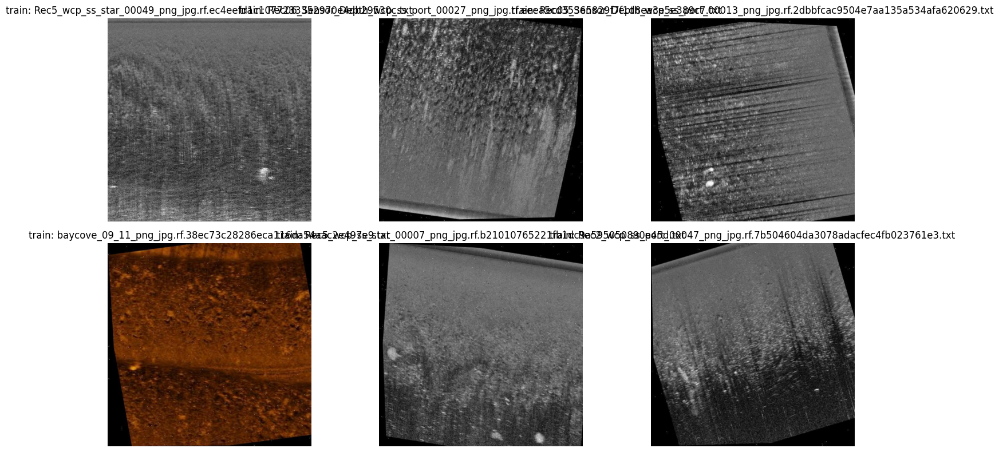

In [ ]:
empty_samples = empty_label_files[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (split, filename) in zip(axes, empty_samples):
    image_path = DATASET_ROOT / split / "images" / filename.replace(".txt", "")

    if not image_path.exists():
        matches = list(
            (DATASET_ROOT / split / "images").glob(
                Path(filename).stem + ".*"
            )
        )
        if not matches:
            ax.axis("off")
            continue
        image_path = matches[0]

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(f"{split}: {filename}")
    ax.axis("off")

for ax in axes[len(empty_samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

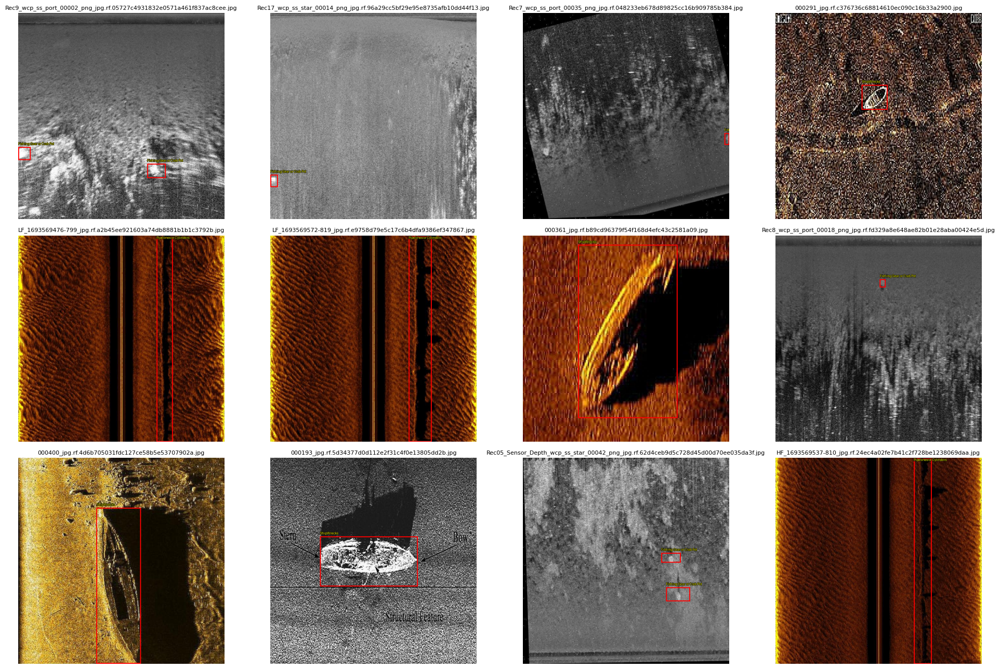

In [ ]:
from PIL import Image, ImageDraw
import random
import matplotlib.pyplot as plt

def audit_annotations(split="train", samples=12):
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    paths = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
        and (label_dir / f"{p.stem}.txt").exists()
        and (label_dir / f"{p.stem}.txt").stat().st_size > 0
    ]

    selected = random.sample(paths, min(samples, len(paths)))
    fig, axes = plt.subplots(3, 4, figsize=(20, 13))
    axes = axes.flatten()

    for ax, path in zip(axes, selected):
        with Image.open(path) as source:
            img = source.convert("RGB")

        draw = ImageDraw.Draw(img)
        label_path = label_dir / f"{path.stem}.txt"

        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            class_id = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            box = [
                (x - w / 2) * img.width,
                (y - h / 2) * img.height,
                (x + w / 2) * img.width,
                (y + h / 2) * img.height,
            ]

            draw.rectangle(box, outline="red", width=3)
            draw.text(
                (box[0], max(0, box[1] - 16)),
                CLASS_NAMES[class_id],
                fill="yellow",
                stroke_width=1,
                stroke_fill="black"
            )

        ax.imshow(img)
        ax.set_title(path.name, fontsize=8)
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

audit_annotations()

## Phase 4: Data Leakage Analysis and Group-Aware Splitting

This phase investigates potential data leakage between the original train, validation, and test splits. It uses perceptual hashes, exact pixel hashes, filename patterns, and inferred recording groups to identify possible duplicates or related images across splits. A new group-aware dataset is then created so that images assigned to the same inferred recording group remain within one split. The resulting dataset is checked for class distribution, missing labels, and residual cross-split near-duplicate candidates.




In [ ]:
# PHASE 4 - CELL 22: FIND NEAR-DUPLICATE IMAGES

!pip -q install ImageHash

import imagehash
from PIL import Image
from itertools import combinations

image_records = []

for split in ["train", "valid", "test"]:
    image_dir = DATASET_ROOT / split / "images"

    for image_path in image_dir.iterdir():
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        with Image.open(image_path) as img:
            img_hash = imagehash.phash(img.convert("RGB"))

        image_records.append({
            "split": split,
            "filename": image_path.name,
            "path": str(image_path),
            "hash": img_hash
        })

duplicate_candidates = []

for a, b in combinations(image_records, 2):
    if a["split"] == b["split"]:
        continue

    distance = a["hash"] - b["hash"]

    if distance <= 8:
        duplicate_candidates.append({
            "split_1": a["split"],
            "image_1": a["filename"],
            "split_2": b["split"],
            "image_2": b["filename"],
            "hash_distance": distance
        })

duplicates_df = pd.DataFrame(duplicate_candidates)

print("Images hashed:", len(image_records))
print("Cross-split near-duplicate candidates:", len(duplicates_df))

if not duplicates_df.empty:
    display(duplicates_df.sort_values("hash_distance").head(30))
else:
    print("No candidates found at this threshold.")

Images hashed: 1315
Cross-split near-duplicate candidates: 171


,split_1,image_1,split_2,image_2,hash_distance
7,train,000206_jpg.rf.3ef154c98828b9b6c46f4e3fd055fa0e...,valid,000324_jpg.rf.d54d0f9932ffab7cff69d199cd3e4202...,0
8,train,000206_jpg.rf.3ef154c98828b9b6c46f4e3fd055fa0e...,test,000285_jpg.rf.8aa65f90b2a2c5fabdf381138192e8ba...,0
23,train,000234_jpg.rf.43ee1d27205beebec43df3d3a98b90e7...,valid,000295_jpg.rf.653d7abccf764a48f76381d9528fe257...,0
45,train,000231_jpg.rf.b43d1a1af6d17ec61e3fac24684c3292...,test,000335_jpg.rf.a835814ee34ff5e6b5b26a5cc9dfd9e3...,0
103,train,Rec7_wcp_ss_star_00004_png_jpg.rf.5b3dec62af58...,valid,Rec7_wcp_ss_star_00004_png_jpg.rf.dbd9cd584d36...,0
105,train,Rec8_wcp_ss_port_00011_png_jpg.rf.b56aadc76206...,valid,Rec8_wcp_ss_port_00011_png_jpg.rf.79545df05566...,0
106,train,000237_jpg.rf.28a6da986e524e847a6d5e286d4ec191...,valid,000329_jpg.rf.dfde712b56dbc0915b3f921d148acf8b...,0
80,train,000225_jpg.rf.8696e81dbfd2d9fdfbf096f106fca046...,test,000326_jpg.rf.d4daba805bcbb49ff0fedbc6795a273b...,0
169,valid,000324_jpg.rf.d54d0f9932ffab7cff69d199cd3e4202...,test,000285_jpg.rf.8aa65f90b2a2c5fabdf381138192e8ba...,0
158,valid,000467_jpg.rf.c2c3500b4f4583d2e1f8db9aea233b04...,test,000473_jpg.rf.113f7cdbeeb73d697ccd044d6133f809...,0


### Phase 4.1: Manual Verification of Near-Duplicate Candidates

Visual inspection is used to review selected candidate pairs. Similarity scores are treated as indicators for further investigation rather than definitive proof of duplicate scenes.


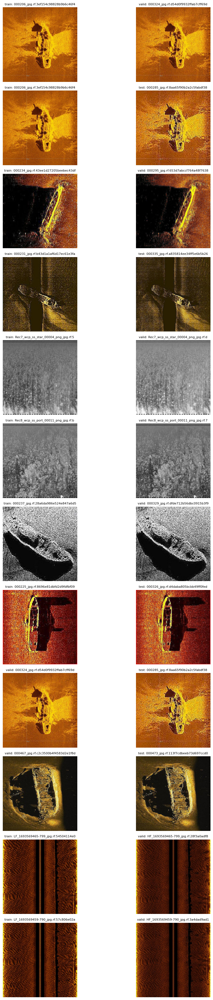

,split_1,image_1,split_2,image_2,hash_distance
0,train,000206_jpg.rf.3ef154c98828b9b6c46f4e3fd055fa0e...,valid,000324_jpg.rf.d54d0f9932ffab7cff69d199cd3e4202...,0
1,train,000206_jpg.rf.3ef154c98828b9b6c46f4e3fd055fa0e...,test,000285_jpg.rf.8aa65f90b2a2c5fabdf381138192e8ba...,0
2,train,000234_jpg.rf.43ee1d27205beebec43df3d3a98b90e7...,valid,000295_jpg.rf.653d7abccf764a48f76381d9528fe257...,0
3,train,000231_jpg.rf.b43d1a1af6d17ec61e3fac24684c3292...,test,000335_jpg.rf.a835814ee34ff5e6b5b26a5cc9dfd9e3...,0
4,train,Rec7_wcp_ss_star_00004_png_jpg.rf.5b3dec62af58...,valid,Rec7_wcp_ss_star_00004_png_jpg.rf.dbd9cd584d36...,0
5,train,Rec8_wcp_ss_port_00011_png_jpg.rf.b56aadc76206...,valid,Rec8_wcp_ss_port_00011_png_jpg.rf.79545df05566...,0
6,train,000237_jpg.rf.28a6da986e524e847a6d5e286d4ec191...,valid,000329_jpg.rf.dfde712b56dbc0915b3f921d148acf8b...,0
7,train,000225_jpg.rf.8696e81dbfd2d9fdfbf096f106fca046...,test,000326_jpg.rf.d4daba805bcbb49ff0fedbc6795a273b...,0
8,valid,000324_jpg.rf.d54d0f9932ffab7cff69d199cd3e4202...,test,000285_jpg.rf.8aa65f90b2a2c5fabdf381138192e8ba...,0
9,valid,000467_jpg.rf.c2c3500b4f4583d2e1f8db9aea233b04...,test,000473_jpg.rf.113f7cdbeeb73d697ccd044d6133f809...,0


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

# Build a lookup for quick access to the image paths
image_lookup = {
    (record["split"], record["filename"]): record["path"]
    for record in image_records
}

# Inspect the closest matches first
pairs_to_review = (
    duplicates_df
    .sort_values("hash_distance")
    .head(12)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    len(pairs_to_review), 2,
    figsize=(12, 3 * len(pairs_to_review))
)

for i, pair in pairs_to_review.iterrows():
    left_key = (pair["split_1"], pair["image_1"])
    right_key = (pair["split_2"], pair["image_2"])

    left_path = image_lookup[left_key]
    right_path = image_lookup[right_key]

    with Image.open(left_path) as img:
        axes[i, 0].imshow(img.convert("RGB"))

    with Image.open(right_path) as img:
        axes[i, 1].imshow(img.convert("RGB"))

    axes[i, 0].set_title(
        f'{pair["split_1"]}: {pair["image_1"][:35]}',
        fontsize=8
    )
    axes[i, 1].set_title(
        f'{pair["split_2"]}: {pair["image_2"][:35]}',
        fontsize=8
    )

    axes[i, 0].set_ylabel(
        f'Pair {i + 1}\nDistance: {pair["hash_distance"]}',
        fontsize=9
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

display(
    pairs_to_review[
        ["split_1", "image_1", "split_2", "image_2", "hash_distance"]
    ]
)

In [ ]:
import hashlib
from collections import defaultdict

def image_pixel_hash(image_path):
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        return hashlib.sha256(img.tobytes()).hexdigest()

pixel_hash_groups = defaultdict(list)

for record in image_records:
    pixel_hash = image_pixel_hash(record["path"])
    pixel_hash_groups[pixel_hash].append(record)

exact_duplicate_groups = []

for pixel_hash, records in pixel_hash_groups.items():
    splits = {record["split"] for record in records}

    if len(records) > 1 and len(splits) > 1:
        exact_duplicate_groups.append({
            "pixel_hash": pixel_hash,
            "records": records,
            "splits": sorted(splits)
        })

print("Exact duplicate groups across splits:", len(exact_duplicate_groups))

for group_number, group in enumerate(exact_duplicate_groups, start=1):
    print(f"\nGroup {group_number} | Splits: {group['splits']}")

    for record in group["records"]:
        print(f"  {record['split']}: {record['filename']}")

Exact duplicate groups across splits: 0


In [ ]:
# PHASE 4 - CELL 25: INSPECT RELATED FILENAME PATTERNS

related_name_pairs = []

for _, row in duplicates_df.iterrows():
    name1 = row["image_1"]
    name2 = row["image_2"]

    # Remove the Roboflow suffix to inspect the underlying names
    base1 = name1.split(".rf.")[0]
    base2 = name2.split(".rf.")[0]

    # Compare names after replacing LF/HF prefixes
    normalized1 = base1.replace("LF_", "XX_").replace("HF_", "XX_")
    normalized2 = base2.replace("LF_", "XX_").replace("HF_", "XX_")

    if normalized1 == normalized2:
        related_name_pairs.append({
            "split_1": row["split_1"],
            "image_1": name1,
            "split_2": row["split_2"],
            "image_2": name2,
            "hash_distance": row["hash_distance"],
            "same_normalized_name": True
        })

related_names_df = pd.DataFrame(related_name_pairs)

print("Pairs with matching normalized filenames:", len(related_names_df))

if not related_names_df.empty:
    display(related_names_df.head(30))

Pairs with matching normalized filenames: 24


,split_1,image_1,split_2,image_2,hash_distance,same_normalized_name
0,train,HF_1693569453-790_jpg.rf.758422df0530e670fd05d...,valid,LF_1693569453-790_jpg.rf.b857ef1e868818afbe899...,6,True
1,train,LF_1693569454-790_jpg.rf.c053f724b204aa12c4ac4...,valid,HF_1693569454-790_jpg.rf.9635605dbeec2b5dbc9cb...,4,True
2,train,LF_1693569467-799_jpg.rf.c3e81d9ad78d5b74bb407...,test,HF_1693569467-799_jpg.rf.e2a041de34c17389c1eb1...,6,True
3,train,LF_1693569406-779_jpg.rf.e2901555298bbbf2a2364...,valid,HF_1693569406-779_jpg.rf.1b810e7ba313b73cdb50b...,8,True
4,train,LF_1693569446-790_jpg.rf.1cc382a979f980c1f3e6c...,valid,HF_1693569446-790_jpg.rf.d95b15e858c9eeb4b148d...,6,True
5,train,LF_1693569445-790_jpg.rf.a664fe5916bc6e2ecfbbe...,valid,HF_1693569445-790_jpg.rf.49be2b9bedeffd39d07b0...,2,True
6,train,LF_1693569448-790_jpg.rf.d75789310609677fc5585...,valid,HF_1693569448-790_jpg.rf.79c9b16be2ddde8489a43...,8,True
7,train,LF_1693569465-799_jpg.rf.54504114e0a1b021bdf29...,valid,HF_1693569465-799_jpg.rf.28f3a0adf81fe90cd2f6d...,2,True
8,train,HF_1693569450-790_jpg.rf.89411f749c418dccc1495...,valid,LF_1693569450-790_jpg.rf.ed42fee4cf41faa4b10ef...,2,True
9,train,LF_1693569444-790_jpg.rf.88cebe44eae0c0d3d4473...,valid,HF_1693569444-790_jpg.rf.de2e60d89dc921a8f2ed3...,8,True


In [ ]:
import re
from collections import defaultdict

def recording_id(filename):
    # Remove the Roboflow export suffix
    base = filename.split(".rf.")[0]

    # Treat LF/HF versions of the same timestamp as one recording
    base = base.replace("LF_", "XX_").replace("HF_", "XX_")

    return base

recording_groups = defaultdict(list)

for record in image_records:
    group_id = recording_id(record["filename"])
    recording_groups[group_id].append(record)

cross_split_groups = []

for group_id, records in recording_groups.items():
    splits = sorted({r["split"] for r in records})

    if len(splits) > 1:
        cross_split_groups.append({
            "recording_id": group_id,
            "splits": ", ".join(splits),
            "num_images": len(records),
            "filenames": [r["filename"] for r in records]
        })

cross_split_df = pd.DataFrame(cross_split_groups)

print("Unique recording groups:", len(recording_groups))
print("Groups spanning multiple splits:", len(cross_split_df))

if not cross_split_df.empty:
    display(cross_split_df.head(40))

Unique recording groups: 1010
Groups spanning multiple splits: 148


,recording_id,splits,num_images,filenames
0,Rec11_wcp_ss_port_00035_png_jpg,"train, valid",2,[Rec11_wcp_ss_port_00035_png_jpg.rf.bbb3396826...
1,XX_1693569391-780_jpg,"train, valid",2,[LF_1693569391-780_jpg.rf.6a14dc88937800c06e2f...
2,XX_1693569554-810_jpg,"train, valid",2,[HF_1693569554-810_jpg.rf.941cc4501cdc4ad6d77a...
3,XX_1693569547-809_jpg,"test, train",2,[LF_1693569547-809_jpg.rf.feb59e244724fc0620eb...
4,XX_1693569393-779_jpg,"train, valid",2,[HF_1693569393-779_jpg.rf.3fbb694e28f349f3b1c5...
5,XX_1693569571-819_jpg,"train, valid",2,[LF_1693569571-819_jpg.rf.24ba403df12eb36c776b...
6,Rec5_wcp_ss_star_00007_png_jpg,"train, valid",2,[Rec5_wcp_ss_star_00007_png_jpg.rf.b2101076522...
7,Rec7_wcp_ss_port_00040_png_jpg,"test, train",2,[Rec7_wcp_ss_port_00040_png_jpg.rf.ad4bde1105c...
8,XX_1693569453-790_jpg,"train, valid",2,[HF_1693569453-790_jpg.rf.758422df0530e670fd05...
9,Rec11_Sensor_Depth_wcp_ss_port_00030_png_jpg,"train, valid",2,[Rec11_Sensor_Depth_wcp_ss_port_00030_png_jpg....


In [ ]:
# PHASE 4 - CELL 29: AUDIT GROUP ASSIGNMENTS

group_audit = []

for group_id, records in recording_groups.items():
    split_counts = Counter(r["split"] for r in records)

    group_audit.append({
        "group_id": group_id,
        "num_images": len(records),
        "train_images": split_counts["train"],
        "valid_images": split_counts["valid"],
        "test_images": split_counts["test"],
        "crosses_splits": len(split_counts) > 1
    })

group_audit_df = pd.DataFrame(group_audit)

print("Groups:", len(group_audit_df))
print("Images represented:", group_audit_df["num_images"].sum())
print("Cross-split groups:", group_audit_df["crosses_splits"].sum())

print("\nGroup size distribution:")
display(group_audit_df["num_images"].value_counts().sort_index().to_frame("groups"))

print("\nImages per group currently crossing splits:")
display(
    group_audit_df[group_audit_df["crosses_splits"]]
    .sort_values("num_images", ascending=False)
    .head(20)
)

Groups: 1010
Images represented: 1315
Cross-split groups: 148

Group size distribution:


,groups
num_images,
1,719
2,280
3,10
6,1



Images per group currently crossing splits:


,group_id,num_images,train_images,valid_images,test_images,crosses_splits
284,Rec11_wcp_ss_star_00007_png_jpg,6,5,0,1,True
63,Rec11_wcp_ss_port_00006_png_jpg,3,2,1,0,True
178,Rec20_wcp_ss_port_00011_png_jpg,3,2,1,0,True
274,Rec6_wcp_ss_star_00004_png_jpg,3,2,1,0,True
508,Rec7_wcp_ss_star_00004_png_jpg,3,2,1,0,True
538,Rec07_Sensor_Depth_wcp_ss_star_00005_png_jpg,3,1,1,1,True
445,Rec19_wcp_ss_port_00069_png_jpg,3,1,1,1,True
279,Rec7_wcp_ss_star_00026_png_jpg,3,1,2,0,True
174,Rec18_wcp_ss_port_00016_png_jpg,3,2,1,0,True
58,XX_1693569453-790_jpg,2,1,1,0,True


In [ ]:

from collections import Counter
from pathlib import Path

print("DATASET_ROOT:", DATASET_ROOT)
print("Images found in image_records:", len(image_records))

print("\n--- Counts by split ---")
for split in ["train", "valid", "test"]:
    records = [r for r in image_records if r["split"] == split]
    print(f"{split}: {len(records)}")

print("\n--- Actual image files in source folders ---")
for split in ["train", "valid", "test"]:
    image_dir = DATASET_ROOT / split / "images"
    files = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]
    print(f"{split}: {len(files)} images in {image_dir}")

print("\n--- Duplicate paths in image_records ---")
path_counts = Counter(str(Path(r["path"]).resolve()) for r in image_records)
duplicate_paths = {p: n for p, n in path_counts.items() if n > 1}
print("Duplicate paths:", len(duplicate_paths))
if duplicate_paths:
    print(list(duplicate_paths.items())[:20])

print("\n--- Duplicate filenames across splits ---")
filename_splits = {}
for r in image_records:
    filename_splits.setdefault(r["filename"], set()).add(r["split"])

repeated_names = {
    name: sorted(splits)
    for name, splits in filename_splits.items()
    if len(splits) > 1
}
print("Filenames appearing in multiple splits:", len(repeated_names))
print(list(repeated_names.items())[:20])


DATASET_ROOT: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.v2i.yolov8
Images found in image_records: 1330

--- Counts by split ---
train: 936
valid: 263
test: 131

--- Actual image files in source folders ---
train: 936 images in /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.v2i.yolov8/train/images
valid: 263 images in /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.v2i.yolov8/valid/images
test: 131 images in /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.v2i.yolov8/test/images

--- Duplicate paths in image_records ---
Duplicate paths: 0

--- Duplicate filenames across splits ---
Filenames appearing in multiple splits: 0
[]


In [ ]:

from pathlib import Path
from collections import Counter
import yaml

print("=== Dataset YAML ===")
yaml_path = DATASET_ROOT / "data.yaml"

with open(yaml_path, "r") as f:
    dataset_config = yaml.safe_load(f)

print(dataset_config)

print("\n=== Image-label consistency ===")
for split in ["train", "valid", "test"]:
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    image_stems = {
        p.stem for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    }
    label_stems = {p.stem for p in label_dir.glob("*.txt")}

    print(f"\n{split}:")
    print("Images:", len(image_stems))
    print("Label files:", len(label_stems))
    print("Images without label files:", len(image_stems - label_stems))
    print("Labels without images:", len(label_stems - image_stems))

    class_counts = Counter()
    empty_labels = 0
    invalid_lines = 0

    for stem in image_stems & label_stems:
        label_path = label_dir / f"{stem}.txt"
        lines = [
            line.strip()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            empty_labels += 1

        for line in lines:
            parts = line.split()
            if len(parts) != 5:
                invalid_lines += 1
                continue
            try:
                class_id = int(parts[0])
                if class_id < 0 or class_id >= int(dataset_config["nc"]):
                    invalid_lines += 1
                else:
                    class_counts[class_id] += 1
            except ValueError:
                invalid_lines += 1

    print("Empty label files:", empty_labels)
    print("Invalid annotation lines:", invalid_lines)
    print("Object counts by class ID:", dict(sorted(class_counts.items())))


=== Dataset YAML ===
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks'], 'roboflow': {'workspace': 'shaik-riyaz-baerg', 'project': 'sss-marine-debris-detection', 'version': 2, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/shaik-riyaz-baerg/sss-marine-debris-detection/dataset/2'}}

=== Image-label consistency ===

train:
Images: 936
Label files: 921
Images without label files: 15
Labels without images: 0
Empty label files: 116
Invalid annotation lines: 0
Object counts by class ID: {0: 620, 1: 321, 2: 188}

valid:
Images: 263
Label files: 263
Images without label files: 0
Labels without images: 0
Empty label files: 37
Invalid annotation lines: 0
Object counts by class ID: {0: 183, 1: 101, 2: 38}

test:
Images: 131
Label files: 131
Images without label files: 0
Labels without images: 0
Empty label files: 9
Invalid annotation lines: 0
Object counts by class I

In [ ]:

# PHASE 4 - CELL 30: CREATE OR REUSE GROUP-AWARE DATASET

import shutil
import pandas as pd
import yaml
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

CLEAN_DATASET_ROOT = (
    PROJECT_DIR / "datasets" / "SSS-Marine-Debris-Detection.grouped"
)

# --------------------------------------------------
# 1. Reuse an existing grouped dataset if available
# --------------------------------------------------
if CLEAN_DATASET_ROOT.exists():
    print("Existing grouped dataset found. Reusing it.")

    for split in ["train", "valid", "test"]:
        image_dir = CLEAN_DATASET_ROOT / split / "images"
        label_dir = CLEAN_DATASET_ROOT / split / "labels"

        if not image_dir.is_dir() or not label_dir.is_dir():
            raise FileNotFoundError(
                f"Missing images or labels directory for split: {split}"
            )

        image_files = [
            p for p in image_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]
        label_stems = {p.stem for p in label_dir.glob("*.txt")}
        image_stems = {p.stem for p in image_files}

        missing_labels = image_stems - label_stems
        extra_labels = label_stems - image_stems

        print(
            f"{split}: {len(image_files)} images, "
            f"{len(label_stems)} labels, "
            f"{len(missing_labels)} missing labels, "
            f"{len(extra_labels)} extra labels"
        )

        if missing_labels or extra_labels:
            raise ValueError(
                f"Image-label mismatch in existing grouped split: {split}"
            )

    GROUPED_YAML = CLEAN_DATASET_ROOT / "data.yaml"

    if not GROUPED_YAML.is_file():
        raise FileNotFoundError(
            f"Grouped dataset YAML is missing: {GROUPED_YAML}"
        )

# --------------------------------------------------
# 2. Build grouped dataset from the current source
# --------------------------------------------------
else:
    records_for_split = []

    for split in ["train", "valid", "test"]:
        image_dir = DATASET_ROOT / split / "images"
        label_dir = DATASET_ROOT / split / "labels"

        if not image_dir.is_dir() or not label_dir.is_dir():
            raise FileNotFoundError(
                f"Missing source images or labels directory: {split}"
            )

        image_files = sorted(
            p for p in image_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        label_stems = {p.stem for p in label_dir.glob("*.txt")}

        for image_path in image_files:
            label_path = label_dir / f"{image_path.stem}.txt"

            # Do not silently treat unlabelled images as background.
            if not label_path.is_file():
                raise FileNotFoundError(
                    f"Image has no label file: {image_path}\n"
                    "Recover its label or confirm it is background-only "
                    "and create an empty label file before continuing."
                )

            records_for_split.append({
                "original_split": split,
                "filename": image_path.name,
                "image_path": image_path,
                "label_path": label_path,
                "group_id": recording_id(image_path.name)
            })

        # Detect label files with no corresponding image.
        image_stems = {p.stem for p in image_files}
        extra_labels = label_stems - image_stems

        if extra_labels:
            raise ValueError(
                f"{split} contains label files without matching images: "
                f"{sorted(extra_labels)[:10]}"
            )

    split_df = pd.DataFrame(records_for_split)

    if split_df.empty:
        raise ValueError("No source images were found.")

    if split_df["image_path"].duplicated().any():
        raise ValueError("Duplicate image paths found in source records.")

    print("Current source image count:", len(split_df))
    print("Images by original split:")
    print(split_df["original_split"].value_counts().to_dict())

    # Group-aware train/validation/test split.
    outer_split = GroupShuffleSplit(
        n_splits=1, test_size=0.10, random_state=SEED
    )

    trainval_idx, test_idx = next(
        outer_split.split(split_df, groups=split_df["group_id"])
    )

    trainval_df = split_df.iloc[trainval_idx].copy()
    test_df = split_df.iloc[test_idx].copy()

    inner_split = GroupShuffleSplit(
        n_splits=1, test_size=0.20 / 0.90, random_state=SEED
    )

    train_idx, valid_idx = next(
        inner_split.split(
            trainval_df, groups=trainval_df["group_id"]
        )
    )

    train_df = trainval_df.iloc[train_idx].copy()
    valid_df = trainval_df.iloc[valid_idx].copy()

    train_df["new_split"] = "train"
    valid_df["new_split"] = "valid"
    test_df["new_split"] = "test"

    new_assignments = pd.concat(
        [train_df, valid_df, test_df], ignore_index=True
    )

    # Verify that each recording group belongs to exactly one split.
    group_split_counts = (
        new_assignments.groupby("group_id")["new_split"].nunique()
    )

    assert group_split_counts.max() == 1, (
        "Leakage detected: a recording group crosses new splits."
    )

    # Build in a temporary directory to avoid leaving a partial dataset
    # if copying or validation fails.
    TEMP_DATASET_ROOT = CLEAN_DATASET_ROOT.with_name(
        CLEAN_DATASET_ROOT.name + "_building"
    )

    if TEMP_DATASET_ROOT.exists():
        raise FileExistsError(
            f"Temporary build directory already exists: "
            f"{TEMP_DATASET_ROOT}\n"
            "Inspect it before removing or reusing it."
        )

    for split in ["train", "valid", "test"]:
        (TEMP_DATASET_ROOT / split / "images").mkdir(
            parents=True, exist_ok=False
        )
        (TEMP_DATASET_ROOT / split / "labels").mkdir(
            parents=True, exist_ok=False
        )

    try:
        for _, row in new_assignments.iterrows():
            image_dest = (
                TEMP_DATASET_ROOT / row["new_split"]
                / "images" / row["filename"]
            )
            label_dest = (
                TEMP_DATASET_ROOT / row["new_split"]
                / "labels" / row["label_path"].name
            )

            shutil.copy2(row["image_path"], image_dest)
            shutil.copy2(row["label_path"], label_dest)

        grouped_config = {
            "path": str(CLEAN_DATASET_ROOT),
            "train": str(CLEAN_DATASET_ROOT / "train" / "images"),
            "val": str(CLEAN_DATASET_ROOT / "valid" / "images"),
            "test": str(CLEAN_DATASET_ROOT / "test" / "images"),
            "nc": len(CLASS_NAMES),
            "names": CLASS_NAMES
        }

        with open(TEMP_DATASET_ROOT / "data.yaml", "w") as f:
            yaml.safe_dump(grouped_config, f, sort_keys=False)

        # Validate copied files before publishing the dataset.
        for split in ["train", "valid", "test"]:
            image_dir = TEMP_DATASET_ROOT / split / "images"
            label_dir = TEMP_DATASET_ROOT / split / "labels"

            images = [
                p for p in image_dir.iterdir()
                if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
            ]
            labels = list(label_dir.glob("*.txt"))

            image_stems = {p.stem for p in images}
            label_stems = {p.stem for p in labels}

            if image_stems != label_stems:
                raise ValueError(
                    f"Validation failed for {split}: "
                    f"{len(image_stems - label_stems)} missing labels, "
                    f"{len(label_stems - image_stems)} extra labels."
                )

        # Publish only after successful validation.
        TEMP_DATASET_ROOT.rename(CLEAN_DATASET_ROOT)

    except Exception:
        print(
            "Dataset creation did not complete. Temporary files, if any, "
            "were left for inspection at:",
            TEMP_DATASET_ROOT
        )
        raise

    GROUPED_YAML = CLEAN_DATASET_ROOT / "data.yaml"
    print("Grouped dataset created:", CLEAN_DATASET_ROOT)

# --------------------------------------------------
# 3. Final split summary
# --------------------------------------------------
print("\nFinal grouped dataset summary:")
for split in ["train", "valid", "test"]:
    image_dir = CLEAN_DATASET_ROOT / split / "images"
    label_dir = CLEAN_DATASET_ROOT / split / "labels"

    image_count = sum(
        1 for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    label_count = len(list(label_dir.glob("*.txt")))

    print(f"{split}: {image_count} images, {label_count} labels")

print("Dataset YAML:", GROUPED_YAML)


Current source image count: 1315
Images by original split:
{'train': 921, 'valid': 263, 'test': 131}
Grouped dataset created: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped

Final grouped dataset summary:
train: 924 images, 924 labels
valid: 258 images, 258 labels
test: 133 images, 133 labels
Dataset YAML: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/data.yaml


In [ ]:
# PHASE 4 - CELL 31: CREATE GROUPED YOLO YAML

GROUPED_YAML = CLEAN_DATASET_ROOT / "data.yaml"

grouped_config = {
    "path": str(CLEAN_DATASET_ROOT),
    "train": str(CLEAN_DATASET_ROOT / "train" / "images"),
    "val": str(CLEAN_DATASET_ROOT / "valid" / "images"),
    "test": str(CLEAN_DATASET_ROOT / "test" / "images"),
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES
}

with open(GROUPED_YAML, "w") as f:
    yaml.safe_dump(grouped_config, f, sort_keys=False)

print(GROUPED_YAML.read_text())

path: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped
train: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/train/images
val: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/valid/images
test: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/test/images
nc: 3
names:
- Fishing Gear or Crab Pot
- Pipelines or Cylinders
- ShipWrecks



In [ ]:

# PHASE 4 - CELL 32: FINAL SPLIT CHECK


new_summary = []
groups_by_split = {}

for split in ["train", "valid", "test"]:
    image_dir = CLEAN_DATASET_ROOT / split / "images"
    label_dir = CLEAN_DATASET_ROOT / split / "labels"

    if not image_dir.is_dir() or not label_dir.is_dir():
        raise FileNotFoundError(f"Missing directories for split: {split}")

    images = [
        p for p in image_dir.iterdir()
        if p.is_file()
    ]
    labels = list(label_dir.glob("*.txt"))

    image_names = {p.stem for p in images}
    label_names = {p.stem for p in labels}

    missing_labels = image_names - label_names
    extra_labels = label_names - image_names

    new_summary.append({
        "split": split,
        "images": len(images),
        "labels": len(labels),
        "missing_labels": len(missing_labels),
        "extra_labels": len(extra_labels)
    })

    groups_by_split[split] = {
        recording_id(p.name) for p in images
    }

display(pd.DataFrame(new_summary))

all_groups = set().union(*groups_by_split.values())

crossing_groups = {
    group for group in all_groups
    if sum(group in groups_by_split[s]
           for s in ["train", "valid", "test"]) > 1
}

print("Unique groups per split:", {
    split: len(groups)
    for split, groups in groups_by_split.items()
})
print("Groups crossing new splits:", len(crossing_groups))
print("Original dataset preserved:", DATASET_ROOT.exists())

assert not crossing_groups, (
    "Some recording groups cross splits. Review the grouping audit."
)


,split,images,labels,missing_labels,extra_labels
0,train,924,924,0,0
1,valid,258,258,0,0
2,test,133,133,0,0


Unique groups per split: {'train': 707, 'valid': 202, 'test': 101}
Groups crossing new splits: 0
Original dataset preserved: True


### Phase 4.2: Grouped Dataset Validation

The newly created grouped dataset is checked for object counts, empty labels, split integrity, YAML configuration, and possible residual near-duplicates before training begins.

In [ ]:
# CELL 33: COUNT OBJECTS IN THE GROUPED DATASET

grouped_class_counts = Counter()
grouped_empty_labels = []

for split in ["train", "valid", "test"]:
    label_dir = CLEAN_DATASET_ROOT / split / "labels"

    for label_path in label_dir.glob("*.txt"):
        lines = label_path.read_text().splitlines()

        if not lines:
            grouped_empty_labels.append((split, label_path.name))
            continue

        for line in lines:
            parts = line.split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            if 0 <= class_id < len(CLASS_NAMES):
                grouped_class_counts[(split, class_id)] += 1

grouped_summary = []

for split in ["train", "valid", "test"]:
    for class_id, class_name in enumerate(CLASS_NAMES):
        grouped_summary.append({
            "split": split,
            "class_name": class_name,
            "object_count": grouped_class_counts[(split, class_id)]
        })

grouped_class_df = pd.DataFrame(grouped_summary)
display(grouped_class_df)

print("Empty label files:", len(grouped_empty_labels))

,split,class_name,object_count
0,train,Fishing Gear or Crab Pot,656
1,train,Pipelines or Cylinders,329
2,train,ShipWrecks,177
3,valid,Fishing Gear or Crab Pot,192
4,valid,Pipelines or Cylinders,74
5,valid,ShipWrecks,51
6,test,Fishing Gear or Crab Pot,74
7,test,Pipelines or Cylinders,54
8,test,ShipWrecks,25


Empty label files: 162


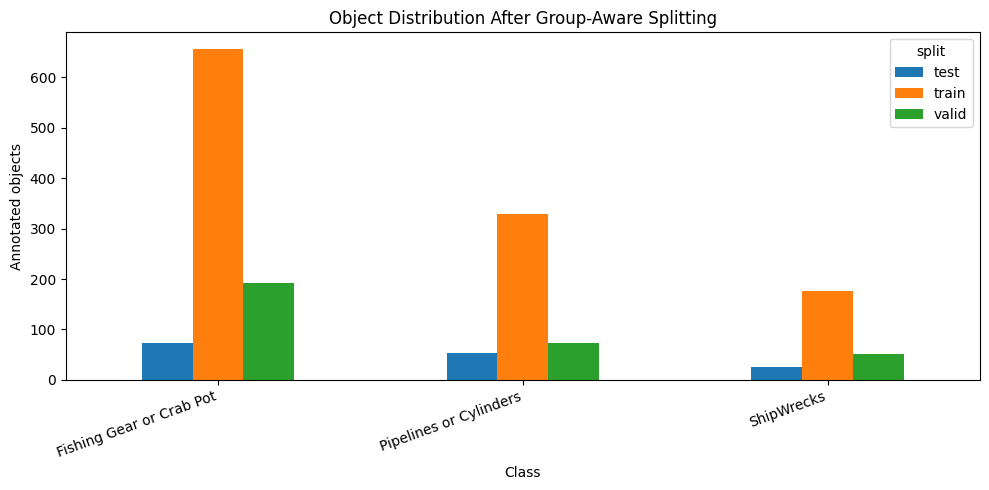

In [ ]:
grouped_pivot = grouped_class_df.pivot(
    index="class_name",
    columns="split",
    values="object_count"
).fillna(0)

grouped_pivot.plot(kind="bar", figsize=(10, 5))

plt.title("Object Distribution After Group-Aware Splitting")
plt.xlabel("Class")
plt.ylabel("Annotated objects")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# CELL 35: NEAR-DUPLICATE CHECK ON GROUPED SPLITS

from PIL import Image as PILImage
import imagehash

grouped_hash_records = []

for split in ["train", "valid", "test"]:
    image_dir = CLEAN_DATASET_ROOT / split / "images"

    for image_path in image_dir.iterdir():
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        with PILImage.open(image_path) as img:
            phash = imagehash.phash(img.convert("RGB"))

        grouped_hash_records.append({
            "split": split,
            "filename": image_path.name,
            "hash": phash
        })

grouped_candidates = []

for i in range(len(grouped_hash_records)):
    a = grouped_hash_records[i]

    for j in range(i + 1, len(grouped_hash_records)):
        b = grouped_hash_records[j]

        if a["split"] == b["split"]:
            continue

        distance = a["hash"] - b["hash"]

        if distance <= 4:
            grouped_candidates.append({
                "split_1": a["split"],
                "image_1": a["filename"],
                "split_2": b["split"],
                "image_2": b["filename"],
                "hash_distance": distance
            })

grouped_duplicates_df = pd.DataFrame(grouped_candidates)

print(
    "Cross-split near-duplicate candidates (distance <= 4):",
    len(grouped_duplicates_df)
)

if not grouped_duplicates_df.empty:
    display(
        grouped_duplicates_df
        .sort_values("hash_distance")
        .head(30)
    )

Cross-split near-duplicate candidates (distance <= 4): 26


,split_1,image_1,split_2,image_2,hash_distance
1,train,000175_jpg.rf.c2866d0d6f019f52bfa79023530e10d9...,valid,000243_jpg.rf.ac9d9c55e032446c00b3bd431b8411a5...,0
9,train,000470_jpg.rf.43217edac85ce666800dda0c06e2bdf8...,valid,000482_jpg.rf.23fc7175b424edfd5001a88e6ee179e3...,0
21,train,000326_jpg.rf.d4daba805bcbb49ff0fedbc6795a273b...,valid,000225_jpg.rf.8696e81dbfd2d9fdfbf096f106fca046...,0
19,train,000329_jpg.rf.dfde712b56dbc0915b3f921d148acf8b...,test,000237_jpg.rf.28a6da986e524e847a6d5e286d4ec191...,0
22,train,000335_jpg.rf.a835814ee34ff5e6b5b26a5cc9dfd9e3...,test,000231_jpg.rf.b43d1a1af6d17ec61e3fac24684c3292...,0
12,train,HF_1693569524-810_jpg.rf.97a5e646aba5d95c74ce4...,test,LF_1693569526-810_jpg.rf.9d6b7758a1a6eeb7df609...,2
8,train,000419_jpg.rf.ae730a01fac74940b35cb0d38aea20fa...,test,000237_jpg.rf.28a6da986e524e847a6d5e286d4ec191...,2
0,train,000150_jpg.rf.ca1a1c36b7723f02279132ebbaffa897...,valid,000373_jpg.rf.46e27634cbee842eacf702169d907bb4...,2
18,train,000238_jpg.rf.3366fd6e7f0633c9665fff0962900601...,valid,000201_jpg.rf.9d27056ce7debfb35961ece8ccf8fa33...,2
11,train,HF_1693569407-779_jpg.rf.3e95b1337e2da8b6156ec...,valid,HF_1693569408-779_jpg.rf.0c4c0443474dca6ed1012...,2


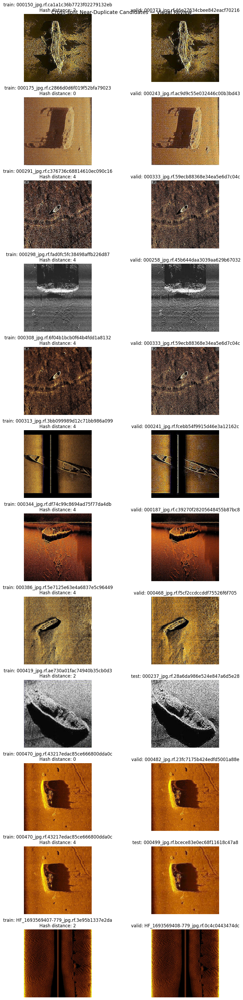

In [ ]:
# CELL 36: Visually inspect cross-split near-duplicate candidates

from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import math

if grouped_duplicates_df.empty:
    print("No cross-split near-duplicate candidates to inspect.")
else:
    candidates = grouped_duplicates_df.head(12).reset_index(drop=True)

    fig, axes = plt.subplots(
        len(candidates), 2,
        figsize=(12, 3.2 * len(candidates))
    )

    if len(candidates) == 1:
        axes = [axes]

    for i, row in candidates.iterrows():
        split1 = row["split_1"]
        split2 = row["split_2"]
        name1 = row["image_1"]
        name2 = row["image_2"]

        path1 = CLEAN_DATASET_ROOT / split1 / "images" / name1
        path2 = CLEAN_DATASET_ROOT / split2 / "images" / name2

        with Image.open(path1) as im:
            img1 = im.convert("RGB").copy()

        with Image.open(path2) as im:
            img2 = im.convert("RGB").copy()

        axes[i][0].imshow(img1, cmap="gray")
        axes[i][0].set_title(
            f"{split1}: {name1[:38]}\nHash distance: {row['hash_distance']}"
        )
        axes[i][0].axis("off")

        axes[i][1].imshow(img2, cmap="gray")
        axes[i][1].set_title(f"{split2}: {name2[:38]}")
        axes[i][1].axis("off")

    plt.suptitle(
        "Cross-split Near-Duplicate Candidates — Visual Review",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

In [ ]:
# CELL 37: Final dataset verification before training

from pathlib import Path
import yaml

DATA_YAML = CLEAN_DATASET_ROOT / "data.yaml"

assert DATA_YAML.exists(), f"Dataset YAML not found: {DATA_YAML}"

with open(DATA_YAML, "r") as f:
    config = yaml.safe_load(f)

print("Dataset YAML:", DATA_YAML)
print("Class names:", config["names"])
print("Number of classes:", config["nc"])

assert config["nc"] == 3, "Expected 3 classes"
assert len(config["names"]) == 3, "Class-name count mismatch"

for split_key in ["train", "val", "test"]:
    image_dir = CLEAN_DATASET_ROOT / config[split_key] if not Path(
        config[split_key]
    ).is_absolute() else Path(config[split_key])

    assert image_dir.exists(), f"Missing directory: {image_dir}"

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    label_dir = image_dir.parent / "labels"

    missing_labels = [
        p.name for p in images
        if not (label_dir / f"{p.stem}.txt").exists()
    ]

    print(
        f"{split_key}: {len(images)} images | "
        f"{len(missing_labels)} missing label files"
    )

    assert images, f"No images found in {split_key}"
    assert not missing_labels, (
        f"Missing labels in {split_key}: {missing_labels[:5]}"
    )

print("\nFinal dataset structure verified.")

Dataset YAML: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/data.yaml
Class names: ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks']
Number of classes: 3
train: 924 images | 0 missing label files
val: 258 images | 0 missing label files
test: 133 images | 0 missing label files

Final dataset structure verified.


## Phase 5: CNN Classification Baseline

This phase develops a baseline image-classification model using square crops generated from annotated marine-debris objects. It verifies annotations, creates and inspects object crops, prepares PyTorch datasets and data loaders, defines the CNN architecture, and trains the model. Training history and validation metrics are recorded to assess how effectively the CNN distinguishes the three classes.

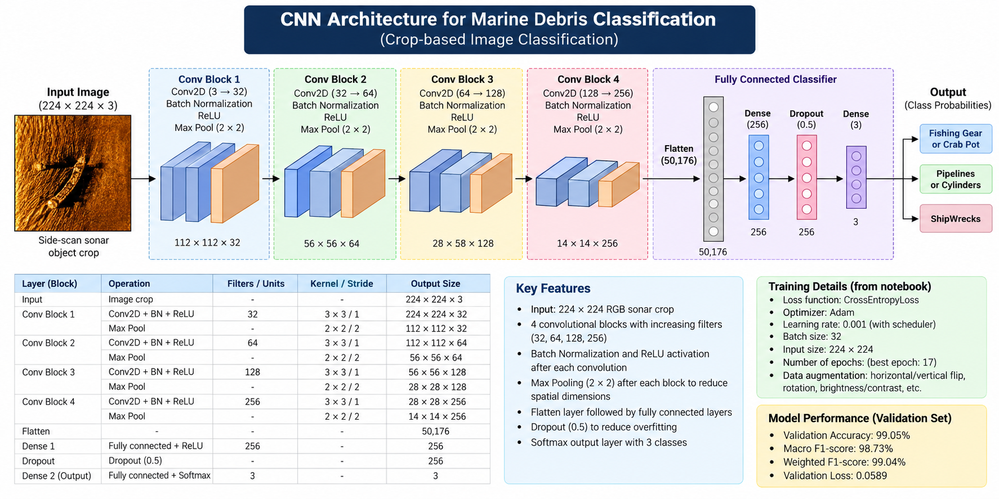

In [ ]:

# PHASE 5 — CELL 38: Verify object annotations for CNN

from collections import Counter

for split in ["train", "valid", "test"]:
    label_dir = CLEAN_DATASET_ROOT / split / "labels"

    class_counts = Counter()
    empty_labels = 0
    total_objects = 0
    malformed_lines = 0

    for label_path in sorted(label_dir.glob("*.txt")):
        lines = [
            line.strip()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            empty_labels += 1
            continue

        for line in lines:
            values = line.split()

            if len(values) != 5:
                malformed_lines += 1
                continue

            try:
                class_id = int(values[0])
                if str(class_id) != values[0] or not 0 <= class_id < len(CLASS_NAMES):
                    malformed_lines += 1
                    continue

                coords = list(map(float, values[1:]))

                if not all(0 <= v <= 1 for v in coords):
                    malformed_lines += 1
                    continue

                if coords[2] <= 0 or coords[3] <= 0:
                    malformed_lines += 1
                    continue

                class_counts[CLASS_NAMES[class_id]] += 1
                total_objects += 1

            except ValueError:
                malformed_lines += 1

    print(f"\n{split.upper()}")
    print("Annotated objects:", total_objects)
    print("Empty-label images:", empty_labels)
    print("Malformed/invalid annotation lines:", malformed_lines)

    for class_name in CLASS_NAMES:
        print(f"  {class_name}: {class_counts[class_name]}")

print("\nAnnotation check complete. Original files unchanged.")



TRAIN
Annotated objects: 1162
Empty-label images: 116
Malformed/invalid annotation lines: 0
  Fishing Gear or Crab Pot: 656
  Pipelines or Cylinders: 329
  ShipWrecks: 177

VALID
Annotated objects: 317
Empty-label images: 29
Malformed/invalid annotation lines: 0
  Fishing Gear or Crab Pot: 192
  Pipelines or Cylinders: 74
  ShipWrecks: 51

TEST
Annotated objects: 153
Empty-label images: 17
Malformed/invalid annotation lines: 0
  Fishing Gear or Crab Pot: 74
  Pipelines or Cylinders: 54
  ShipWrecks: 25

Annotation check complete. Original files unchanged.


In [ ]:

# PHASE 5 — CELL 39: Generate square object crops for CNN

from pathlib import Path
from PIL import Image
from collections import Counter
import json
import time

SQUARE_CROP_ROOT = (
    PROJECT_DIR / "datasets" / "SSS-Marine-Debris-CNN-Square-Crops"
)

TARGET_SIZE = 128
CONTEXT_SCALE = 1.5
MIN_CROP_SIDE = 16
PROGRESS_EVERY = 100

# Safety: never overwrite a previous crop dataset.
if SQUARE_CROP_ROOT.exists():
    raise FileExistsError(
        f"Output folder already exists:\n{SQUARE_CROP_ROOT}\n"
        "Inspect it before choosing a different output path."
    )

SQUARE_CROP_ROOT.mkdir(parents=True, exist_ok=False)

crop_counts = {
    split: Counter()
    for split in ["train", "valid", "test"]
}

start_time = time.time()
images_processed = 0
objects_processed = 0
invalid_boxes = 0

for split in ["train", "valid", "test"]:
    image_dir = CLEAN_DATASET_ROOT / split / "images"
    label_dir = CLEAN_DATASET_ROOT / split / "labels"

    image_paths = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"\nProcessing {split}: {len(image_paths)} images")

    for image_path in image_paths:
        label_path = label_dir / f"{image_path.stem}.txt"

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        width, height = image.size

        for obj_idx, line in enumerate(label_path.read_text().splitlines()):
            if not line.strip():
                continue

            values = line.split()

            try:
                if len(values) != 5:
                    invalid_boxes += 1
                    continue

                class_float, xc, yc, bw, bh = map(float, values)
                class_id = int(class_float)

                if (
                    class_float != class_id
                    or not 0 <= class_id < len(CLASS_NAMES)
                    or not all(0 <= v <= 1 for v in [xc, yc, bw, bh])
                    or bw <= 0
                    or bh <= 0
                ):
                    invalid_boxes += 1
                    continue

                center_x, center_y = xc * width, yc * height
                box_w, box_h = bw * width, bh * height

                # Square crop with context around the annotated object.
                side = max(box_w, box_h) * CONTEXT_SCALE
                side = max(side, MIN_CROP_SIDE)

                x1 = round(center_x - side / 2)
                y1 = round(center_y - side / 2)
                x2 = round(center_x + side / 2)
                y2 = round(center_y + side / 2)

                # PIL supports crop regions extending beyond image boundaries.
                crop = image.crop((x1, y1, x2, y2))
                crop = crop.resize(
                    (TARGET_SIZE, TARGET_SIZE),
                    Image.Resampling.LANCZOS
                )

                class_name = CLASS_NAMES[class_id]
                class_dir = SQUARE_CROP_ROOT / split / class_name
                class_dir.mkdir(parents=True, exist_ok=True)

                crop_path = (
                    class_dir / f"{image_path.stem}_obj{obj_idx:03d}.jpg"
                )
                crop.save(crop_path, format="JPEG", quality=90)

                crop_counts[split][class_name] += 1
                objects_processed += 1

            except (ValueError, OSError) as exc:
                invalid_boxes += 1
                print(f"Skipped annotation in {label_path.name}: {exc}")

        images_processed += 1

        if images_processed % PROGRESS_EVERY == 0:
            elapsed = time.time() - start_time
            print(
                f"Progress: {images_processed} images | "
                f"{objects_processed} crops | "
                f"{elapsed:.1f} seconds elapsed"
            )

        # Release the image before moving to the next file.
        image.close()

metadata = {
    "source_dataset": str(CLEAN_DATASET_ROOT),
    "target_size": TARGET_SIZE,
    "context_scale": CONTEXT_SCALE,
    "class_names": CLASS_NAMES,
    "crop_counts": {
        split: dict(counts)
        for split, counts in crop_counts.items()
    },
    "invalid_annotations_skipped": invalid_boxes,
}

with open(SQUARE_CROP_ROOT / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\nCrop generation complete.")
print("Output:", SQUARE_CROP_ROOT)

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")
    for class_name in CLASS_NAMES:
        print(f"  {class_name}: {crop_counts[split][class_name]}")
    print("  Total:", sum(crop_counts[split].values()))

print("\nTotal crops:", objects_processed)
print("Invalid annotations skipped:", invalid_boxes)
print(f"Elapsed time: {time.time() - start_time:.1f} seconds")



Processing train: 924 images
Progress: 100 images | 102 crops | 2.4 seconds elapsed
Progress: 200 images | 199 crops | 4.2 seconds elapsed
Progress: 300 images | 347 crops | 6.8 seconds elapsed
Progress: 400 images | 452 crops | 9.4 seconds elapsed
Progress: 500 images | 579 crops | 12.5 seconds elapsed
Progress: 600 images | 674 crops | 14.1 seconds elapsed
Progress: 700 images | 843 crops | 16.3 seconds elapsed
Progress: 800 images | 996 crops | 18.3 seconds elapsed
Progress: 900 images | 1134 crops | 20.2 seconds elapsed

Processing valid: 258 images
Progress: 1000 images | 1251 crops | 22.4 seconds elapsed
Progress: 1100 images | 1350 crops | 24.7 seconds elapsed

Processing test: 133 images
Progress: 1200 images | 1497 crops | 26.8 seconds elapsed
Progress: 1300 images | 1613 crops | 29.3 seconds elapsed

Crop generation complete.
Output: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-CNN-Square-Crops

TRAIN
  Fishing Gear or Crab Pot: 656
  Pipelines or Cylinder


TRAIN
Fishing Gear or Crab Pot: 656 crops | invalid or wrong-sized: 0
Pipelines or Cylinders: 329 crops | invalid or wrong-sized: 0
ShipWrecks: 177 crops | invalid or wrong-sized: 0
Split total: 1162

VALID
Fishing Gear or Crab Pot: 192 crops | invalid or wrong-sized: 0
Pipelines or Cylinders: 74 crops | invalid or wrong-sized: 0
ShipWrecks: 51 crops | invalid or wrong-sized: 0
Split total: 317

TEST
Fishing Gear or Crab Pot: 74 crops | invalid or wrong-sized: 0
Pipelines or Cylinders: 54 crops | invalid or wrong-sized: 0
ShipWrecks: 25 crops | invalid or wrong-sized: 0
Split total: 153


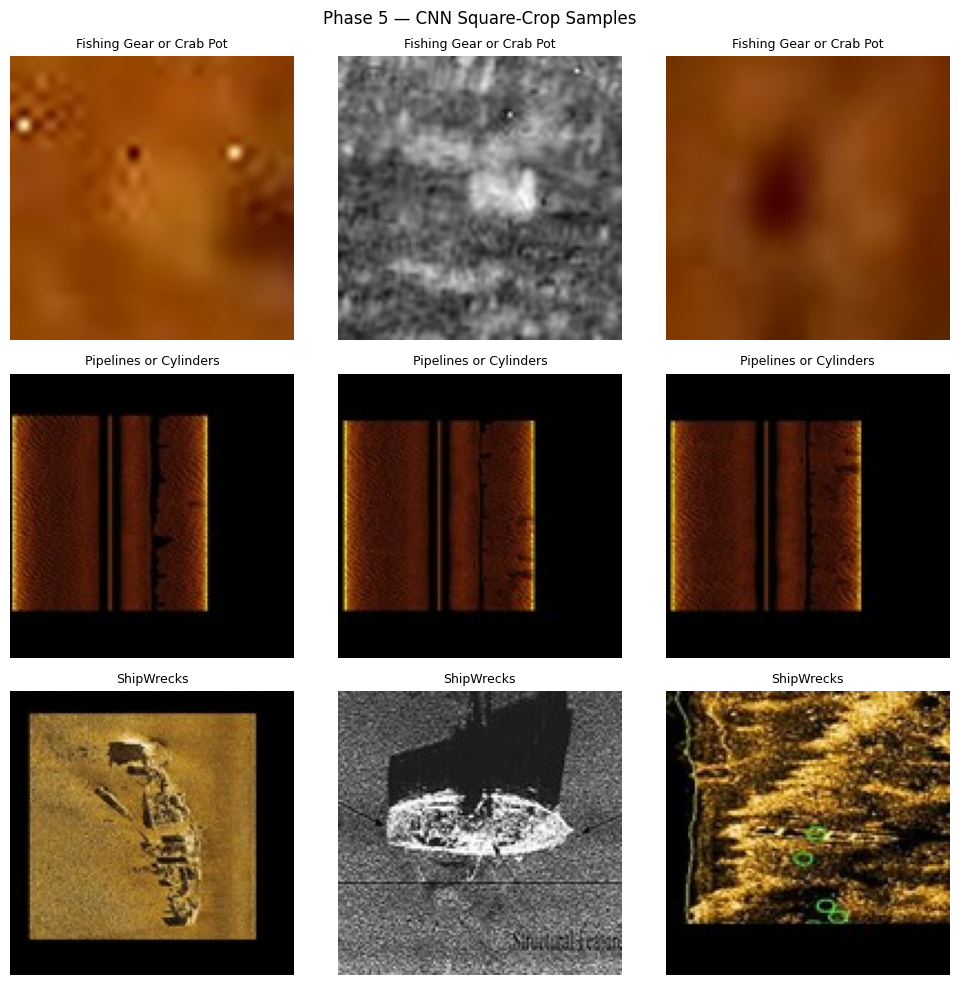


SUMMARY
Total crops: 1632
All crops are valid 128x128 images: True
Split totals: {'train': 1162, 'valid': 317, 'test': 153}


In [ ]:

# PHASE 5 — CELL 40: Validate and visualize CNN square crops

from PIL import Image
from collections import Counter
import random
import matplotlib.pyplot as plt

random.seed(SEED)

assert SQUARE_CROP_ROOT.exists(), "CNN crop dataset not found."

split_totals = {}
all_valid = True

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")

    split_total = 0

    for class_name in CLASS_NAMES:
        class_dir = SQUARE_CROP_ROOT / split / class_name

        files = (
            sorted(
                p for p in class_dir.iterdir()
                if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
            )
            if class_dir.exists() else []
        )

        bad_images = 0

        for path in files:
            try:
                with Image.open(path) as im:
                    if im.size != (128, 128):
                        bad_images += 1
                    im.verify()
            except Exception:
                bad_images += 1

        print(
            f"{class_name}: {len(files)} crops | "
            f"invalid or wrong-sized: {bad_images}"
        )

        split_total += len(files)
        all_valid = all_valid and bad_images == 0

    split_totals[split] = split_total
    print("Split total:", split_total)

# Show 3 training crops per class
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for row, class_name in enumerate(CLASS_NAMES):
    class_dir = SQUARE_CROP_ROOT / "train" / class_name
    files = sorted(
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    selected = random.sample(files, min(3, len(files)))

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(selected):
            with Image.open(selected[col]) as im:
                ax.imshow(im.convert("RGB"))

            ax.set_title(class_name, fontsize=9)

plt.suptitle("Phase 5 — CNN Square-Crop Samples")
plt.tight_layout()
plt.show()

print("\nSUMMARY")
print("Total crops:", sum(split_totals.values()))
print("All crops are valid 128x128 images:", all_valid)
print("Split totals:", split_totals)


In [ ]:

# PHASE 5 — CELL 41: Create PyTorch datasets and data loaders

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Reproducibility
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMAGE_SIZE = 128
BATCH_SIZE = 32
NUM_WORKERS = 2

# ImageNet normalization is a common baseline for RGB images.
# We will train the CNN from scratch, without pretrained weights.
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    root=str(SQUARE_CROP_ROOT / "train"),
    transform=transform
)

valid_dataset = datasets.ImageFolder(
    root=str(SQUARE_CROP_ROOT / "valid"),
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=str(SQUARE_CROP_ROOT / "test"),
    transform=transform
)

# Ensure every split uses the same class-to-index mapping.
print("Class mapping:", train_dataset.class_to_idx)

assert train_dataset.class_to_idx == valid_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx
assert len(train_dataset) == 1162
assert len(valid_dataset) == 317
assert len(test_dataset) == 153

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    generator=generator
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Check one batch
images, labels = next(iter(train_loader))

print("\nDevice:", device)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Test samples:", len(test_dataset))
print("Number of training batches:", len(train_loader))
print("One image batch shape:", images.shape)
print("One label batch shape:", labels.shape)
print("Image tensor dtype:", images.dtype)
print("Label tensor dtype:", labels.dtype)

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.ndim == 1

print("\nPyTorch data pipeline ready.")


Class mapping: {'Fishing Gear or Crab Pot': 0, 'Pipelines or Cylinders': 1, 'ShipWrecks': 2}

Device: cuda
Training samples: 1162
Validation samples: 317
Test samples: 153
Number of training batches: 37
One image batch shape: torch.Size([32, 3, 128, 128])
One label batch shape: torch.Size([32])
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64

PyTorch data pipeline ready.


In [ ]:

# PHASE 5 — CELL 42: Define the CNN classification model

import torch
import torch.nn as nn

class MarineDebrisCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()

        self.features = nn.Sequential(
            # Input: 3 x 128 x 128
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 32 x 64 x 64

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 64 x 32 x 32

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 128 x 16 x 16

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 256 x 8 x 8
        )

        # Reduces the feature map to a fixed-size representation.
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


model = MarineDebrisCNN(num_classes=len(CLASS_NAMES)).to(device)

# Count trainable parameters
trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

# Test the architecture with one batch
model.eval()

with torch.no_grad():
    sample_logits = model(images.to(device))

print(model)
print("\nDevice:", device)
print("Trainable parameters:", f"{trainable_params:,}")
print("Input batch shape:", tuple(images.shape))
print("Output logits shape:", tuple(sample_logits.shape))

assert sample_logits.shape == (images.shape[0], len(CLASS_NAMES))

print("\nCNN architecture verified.")


MarineDebrisCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0

In [ ]:

# PHASE 5 — CELL 43: Configure CNN training

import torch
import torch.nn as nn
from pathlib import Path

# Training configuration
EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 6

# Handle class imbalance using inverse-frequency class weights.
train_class_counts = torch.bincount(
    torch.tensor(train_dataset.targets),
    minlength=len(CLASS_NAMES)
).float()

class_weights = (
    train_class_counts.sum() / (len(CLASS_NAMES) * train_class_counts)
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# Save model checkpoints separately from the dataset.
CNN_RUN_DIR = PROJECT_DIR / "runs" / "marine_debris" / "cnn_baseline"
CNN_RUN_DIR.mkdir(parents=True, exist_ok=True)

BEST_CNN_PATH = CNN_RUN_DIR / "best_cnn_model.pth"
LAST_CNN_PATH = CNN_RUN_DIR / "last_cnn_model.pth"

print("Training configuration ready")
print("-" * 40)
print("Device:", device)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Initial learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Early stopping patience:", PATIENCE)

print("\nTraining class counts:")
for idx, class_name in enumerate(train_dataset.classes):
    print(f"{class_name}: {int(train_class_counts[idx].item())}")

print("\nClass weights:")
for idx, class_name in enumerate(train_dataset.classes):
    print(f"{class_name}: {class_weights[idx].item():.4f}")

print("\nBest checkpoint:", BEST_CNN_PATH)
print("Last checkpoint:", LAST_CNN_PATH)


Training configuration ready
----------------------------------------
Device: cuda
Epochs: 30
Batch size: 32
Initial learning rate: 0.001
Weight decay: 0.0001
Early stopping patience: 6

Training class counts:
Fishing Gear or Crab Pot: 656
Pipelines or Cylinders: 329
ShipWrecks: 177

Class weights:
Fishing Gear or Crab Pot: 0.5904
Pipelines or Cylinders: 1.1773
ShipWrecks: 2.1883

Best checkpoint: /content/drive/MyDrive/dl case study/runs/marine_debris/cnn_baseline/best_cnn_model.pth
Last checkpoint: /content/drive/MyDrive/dl case study/runs/marine_debris/cnn_baseline/last_cnn_model.pth


In [ ]:

# PHASE 5 — CELL 44: Train the CNN baseline

import copy
import json
import time
import torch
from torch.utils.data import DataLoader

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

# Start with a fresh best-checkpoint selection for this training run.
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    # ---------------- TRAINING ----------------
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(batch_images)
        loss = criterion(logits, batch_labels)

        loss.backward()
        optimizer.step()

        batch_size_actual = batch_labels.size(0)
        train_loss_sum += loss.item() * batch_size_actual
        train_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        train_total += batch_size_actual

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ---------------- VALIDATION ----------------
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in valid_loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_labels = batch_labels.to(device, non_blocking=True)

            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            batch_size_actual = batch_labels.size(0)
            val_loss_sum += loss.item() * batch_size_actual
            val_correct += (
                logits.argmax(dim=1) == batch_labels
            ).sum().item()
            val_total += batch_size_actual

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    # Adjust learning rate using validation loss.
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["learning_rate"].append(current_lr)

    # Save the latest state, including optimizer state.
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_loss": val_loss,
        "class_names": train_dataset.classes,
        "history": history
    }, LAST_CNN_PATH)

    # Select best model by validation loss.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "class_names": train_dataset.classes,
            "history": history
        }, BEST_CNN_PATH)
        status = "Best checkpoint saved"
    else:
        epochs_without_improvement += 1
        status = (
            f"No improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    elapsed = time.time() - epoch_start

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | "
        f"train_acc={train_accuracy:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"val_acc={val_accuracy:.4f} | "
        f"lr={current_lr:.2e} | "
        f"{elapsed:.1f}s | {status}",
        flush=True
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

# Save training history for later plots and reporting.
history_path = CNN_RUN_DIR / "training_history.json"

with open(history_path, "w") as f:
    json.dump(history, f, indent=2)

print("\nCNN training finished.")
print("Epochs completed:", len(history["train_loss"]))
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Total elapsed time: {(time.time() - start_time) / 60:.2f} minutes")
print("Best checkpoint:", BEST_CNN_PATH)
print("Last checkpoint:", LAST_CNN_PATH)
print("History:", history_path)


Epoch 01/30 | train_loss=0.3358 | train_acc=0.8830 | val_loss=0.2860 | val_acc=0.8991 | lr=1.00e-03 | 3.7s | Best checkpoint saved
Epoch 02/30 | train_loss=0.1447 | train_acc=0.9552 | val_loss=0.0772 | val_acc=0.9842 | lr=1.00e-03 | 3.4s | Best checkpoint saved
Epoch 03/30 | train_loss=0.1115 | train_acc=0.9613 | val_loss=0.1454 | val_acc=0.9558 | lr=1.00e-03 | 3.2s | No improvement: 1/6
Epoch 04/30 | train_loss=0.1487 | train_acc=0.9501 | val_loss=0.1210 | val_acc=0.9558 | lr=1.00e-03 | 3.2s | No improvement: 2/6
Epoch 05/30 | train_loss=0.0909 | train_acc=0.9716 | val_loss=0.0814 | val_acc=0.9716 | lr=5.00e-04 | 3.2s | No improvement: 3/6
Epoch 06/30 | train_loss=0.0663 | train_acc=0.9811 | val_loss=0.0715 | val_acc=0.9905 | lr=5.00e-04 | 3.4s | Best checkpoint saved
Epoch 07/30 | train_loss=0.0452 | train_acc=0.9854 | val_loss=0.0876 | val_acc=0.9685 | lr=5.00e-04 | 3.3s | No improvement: 1/6
Epoch 08/30 | train_loss=0.1465 | train_acc=0.9613 | val_loss=0.0762 | val_acc=0.9748 | lr=

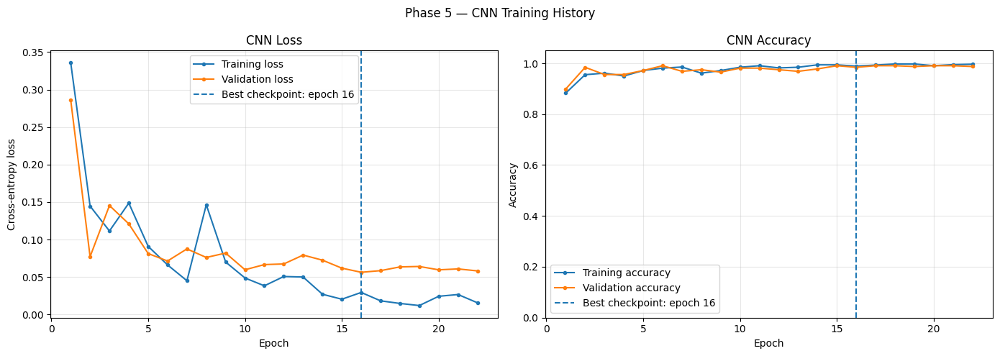

Best epoch: 16
Best validation loss: 0.0564
Validation accuracy at best epoch: 98.42%


In [ ]:

# PHASE 5 — CELL 45: Plot CNN training history

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(epochs, history["train_loss"], marker="o",
             markersize=3, label="Training loss")
axes[0].plot(epochs, history["val_loss"], marker="o",
             markersize=3, label="Validation loss")
axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best checkpoint: epoch {best_epoch}"
)
axes[0].set_title("CNN Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(epochs, history["train_accuracy"], marker="o",
             markersize=3, label="Training accuracy")
axes[1].plot(epochs, history["val_accuracy"], marker="o",
             markersize=3, label="Validation accuracy")
axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best checkpoint: epoch {best_epoch}"
)
axes[1].set_title("CNN Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Phase 5 — CNN Training History")
plt.tight_layout()
plt.show()

print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy at best epoch: "
      f"{history['val_accuracy'][best_epoch - 1] * 100:.2f}%")


Best checkpoint epoch: 16
Checkpoint validation loss: 0.0564
Validation accuracy: 98.42%

Classification report:
                          precision    recall  f1-score   support

Fishing Gear or Crab Pot     0.9845    0.9896    0.9870       192
  Pipelines or Cylinders     1.0000    1.0000    1.0000        74
              ShipWrecks     0.9600    0.9412    0.9505        51

                accuracy                         0.9842       317
               macro avg     0.9815    0.9769    0.9792       317
            weighted avg     0.9841    0.9842    0.9842       317



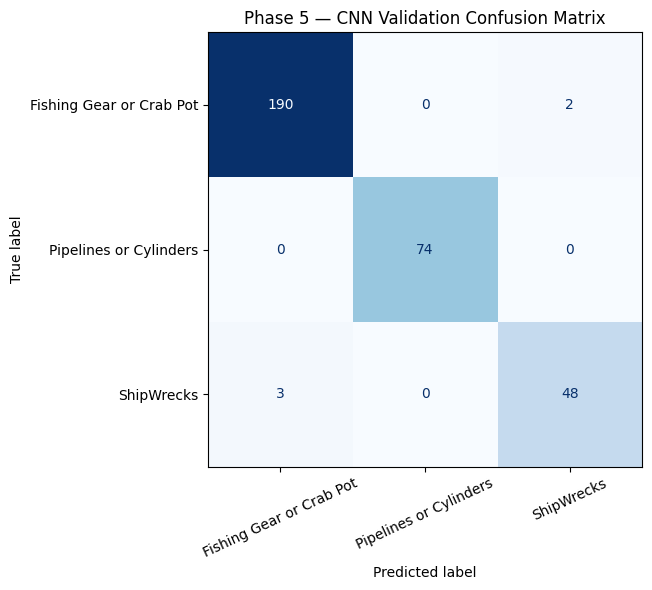

In [ ]:

# PHASE 5 — CELL 46: Evaluate CNN on validation data

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

# Load the best checkpoint selected using validation loss.
checkpoint = torch.load(
    BEST_CNN_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for batch_images, batch_labels in valid_loader:
        batch_images = batch_images.to(device, non_blocking=True)

        logits = model(batch_images)
        predictions = logits.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions.tolist())
        y_true.extend(batch_labels.numpy().tolist())

class_names = train_dataset.classes
class_ids = list(range(len(class_names)))

print("Best checkpoint epoch:", checkpoint["epoch"])
print(f"Checkpoint validation loss: {checkpoint['val_loss']:.4f}")
print(f"Validation accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=class_ids)

fig, ax = plt.subplots(figsize=(8, 6))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=25,
    colorbar=False
)
plt.title("Phase 5 — CNN Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# PHASE 5 — CELL 47: Save CNN validation metrics

import json
import pandas as pd
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

validation_results = {
    "phase": "Phase 5 - CNN classification baseline",
    "checkpoint": str(BEST_CNN_PATH),
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_loss": float(checkpoint["val_loss"]),
    "validation_samples": len(y_true),
    "validation_accuracy": float(accuracy_score(y_true, y_pred)),
    "classification_report": report_dict,
    "confusion_matrix": cm.tolist(),
    "class_names": class_names,
}

results_path = CNN_RUN_DIR / "validation_results.json"
confusion_path = CNN_RUN_DIR / "validation_confusion_matrix.csv"
report_path = CNN_RUN_DIR / "validation_classification_report.csv"

with open(results_path, "w") as f:
    json.dump(validation_results, f, indent=2)

pd.DataFrame(
    cm,
    index=[f"Actual: {name}" for name in class_names],
    columns=[f"Predicted: {name}" for name in class_names]
).to_csv(confusion_path)

pd.DataFrame(report_dict).transpose().to_csv(report_path)

print("Validation results saved:")
print(results_path)
print(confusion_path)
print(report_path)
print("\nValidation accuracy:",
      f"{validation_results['validation_accuracy'] * 100:.2f}%")
print("Best checkpoint epoch:", validation_results["best_epoch"])
print("Test data has not been evaluated.")


Validation results saved:
/content/drive/MyDrive/dl case study/runs/marine_debris/cnn_baseline/validation_results.json
/content/drive/MyDrive/dl case study/runs/marine_debris/cnn_baseline/validation_confusion_matrix.csv
/content/drive/MyDrive/dl case study/runs/marine_debris/cnn_baseline/validation_classification_report.csv

Validation accuracy: 98.42%
Best checkpoint epoch: 16
Test data has not been evaluated.


CNN HELD-OUT TEST RESULTS
Test crops: 153
Accuracy: 0.9804
Macro F1: 0.9729
Weighted F1: 0.9803

Classification report:
                          precision    recall  f1-score   support

Fishing Gear or Crab Pot     0.9733    0.9865    0.9799        74
  Pipelines or Cylinders     1.0000    1.0000    1.0000        54
              ShipWrecks     0.9583    0.9200    0.9388        25

                accuracy                         0.9804       153
               macro avg     0.9772    0.9688    0.9729       153
            weighted avg     0.9803    0.9804    0.9803       153



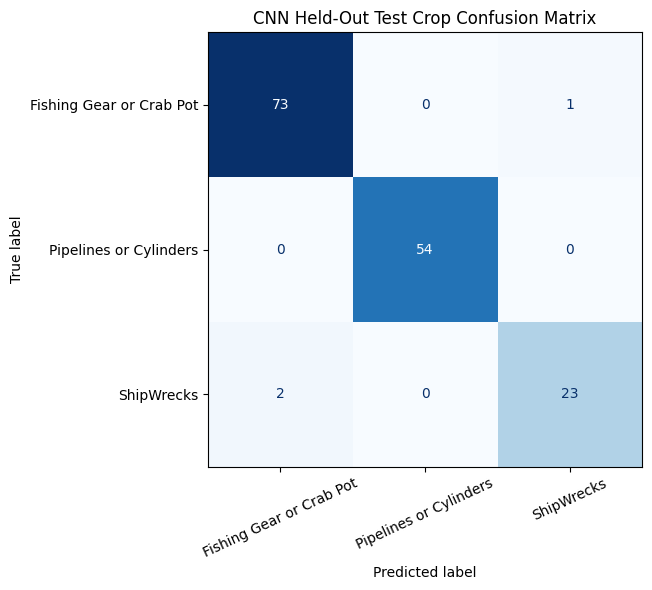

Saved CNN test results: /content/drive/MyDrive/dl case study/runs/marine_debris/cnn_baseline/test_results.json


In [ ]:
# PHASE 5 — ADDITIONAL CELL: Evaluate the saved CNN on held-out test crops


import json
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_fscore_support
)
import matplotlib.pyplot as plt

CNN_RUN_DIR = PROJECT_DIR / "runs" / "marine_debris" / "cnn_baseline"
BEST_CNN_PATH = CNN_RUN_DIR / "best_cnn_model.pth"
assert BEST_CNN_PATH.is_file(), f"CNN checkpoint not found: {BEST_CNN_PATH}"
assert len(test_dataset) == 153, f"Expected 153 test crops; found {len(test_dataset)}"

checkpoint_test = torch.load(BEST_CNN_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint_test["model_state_dict"])
model.to(device)
model.eval()

cnn_test_true, cnn_test_pred = [], []
with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        logits = model(batch_images.to(device, non_blocking=True))
        cnn_test_pred.extend(logits.argmax(dim=1).cpu().tolist())
        cnn_test_true.extend(batch_labels.tolist())

cnn_test_report = classification_report(
    cnn_test_true, cnn_test_pred,
    labels=list(range(len(class_names))),
    target_names=class_names, output_dict=True, zero_division=0
)
cnn_test_results = {
    "model": "MarineDebrisCNN",
    "evaluation_split": "test",
    "test_crops": len(cnn_test_true),
    "accuracy": float(accuracy_score(cnn_test_true, cnn_test_pred)),
    "macro_precision": float(precision_recall_fscore_support(cnn_test_true, cnn_test_pred, average="macro", zero_division=0)[0]),
    "macro_recall": float(precision_recall_fscore_support(cnn_test_true, cnn_test_pred, average="macro", zero_division=0)[1]),
    "macro_f1": float(precision_recall_fscore_support(cnn_test_true, cnn_test_pred, average="macro", zero_division=0)[2]),
    "weighted_f1": float(precision_recall_fscore_support(cnn_test_true, cnn_test_pred, average="weighted", zero_division=0)[2]),
    "class_names": class_names,
    "classification_report": cnn_test_report,
    "confusion_matrix": confusion_matrix(cnn_test_true, cnn_test_pred, labels=list(range(len(class_names)))).tolist(),
    "checkpoint": str(BEST_CNN_PATH),
    "note": "Crop-classification metrics; not directly comparable to YOLO full-image detection metrics."
}

cnn_test_json = CNN_RUN_DIR / "test_results.json"
with open(cnn_test_json, "w", encoding="utf-8") as f:
    json.dump(cnn_test_results, f, indent=2)

print("CNN HELD-OUT TEST RESULTS")
print("Test crops:", cnn_test_results["test_crops"])
print(f"Accuracy: {cnn_test_results['accuracy']:.4f}")
print(f"Macro F1: {cnn_test_results['macro_f1']:.4f}")
print(f"Weighted F1: {cnn_test_results['weighted_f1']:.4f}")
print("\nClassification report:")
print(classification_report(cnn_test_true, cnn_test_pred, labels=list(range(len(class_names))), target_names=class_names, digits=4, zero_division=0))

cm_test = confusion_matrix(cnn_test_true, cnn_test_pred, labels=list(range(len(class_names))))
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=25, colorbar=False)
plt.title("CNN Held-Out Test Crop Confusion Matrix")
plt.tight_layout()
plt.show()
print("Saved CNN test results:", cnn_test_json)


## Phase 6: YOLOv8 Object Detection

This phase configures and trains a YOLOv8n object-detection model on the grouped dataset. It verifies the dataset configuration and annotations, initializes the pretrained detection model, and performs training using a fresh run directory. Training outputs and artifacts are inspected so the selected checkpoint can be used for held-out test evaluation.

In [ ]:

# PHASE 6 — CELL 48: YOLO setup and reproducibility

%pip install -q ultralytics

import random
import numpy as np
import torch
import ultralytics

from pathlib import Path
from ultralytics import YOLO

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable; training will be slower.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.188
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:

# PHASE 6 - CELL 49: Configure YOLO training/evaluation paths

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/dl case study")

CLEAN_DATASET_ROOT = (
    PROJECT_DIR / "datasets" / "SSS-Marine-Debris-Detection.grouped"
)
DATA_YAML = CLEAN_DATASET_ROOT / "data.yaml"

YOLO_PROJECT_DIR = PROJECT_DIR / "runs" / "marine_debris"
YOLO_PHASE6_RUN_DIR = YOLO_PROJECT_DIR / "yolov8n_phase6_fresh"
YOLO_BEST_MODEL = YOLO_PHASE6_RUN_DIR / "weights" / "best.pt"

CLASS_NAMES = [
    "Fishing Gear or Crab Pot",
    "Pipelines or Cylinders",
    "ShipWrecks",
]
SEED = 42

assert DATA_YAML.is_file(), f"Dataset YAML missing: {DATA_YAML}"

print("Dataset YAML:", DATA_YAML)
print("YOLO run directory:", YOLO_PHASE6_RUN_DIR)

if YOLO_BEST_MODEL.is_file():
    print("Existing trained checkpoint found:", YOLO_BEST_MODEL)
    print("Use this checkpoint for evaluation; do not retrain.")
else:
    print("No trained checkpoint found in this account.")
    print("A fresh YOLO training run is required.")

print("CUDA available:", __import__("torch").cuda.is_available())


Dataset YAML: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/data.yaml
YOLO run directory: /content/drive/MyDrive/dl case study/runs/marine_debris/yolov8n_phase6_fresh
No trained checkpoint found in this account.
A fresh YOLO training run is required.
CUDA available: True


In [ ]:

# PHASE 6 — CELL 50: Validate YOLO dataset and annotations

import yaml
from collections import Counter

with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

print("Dataset YAML configuration:")
print(data_config)

assert data_config["nc"] == 3, "Expected exactly 3 classes."
assert data_config["names"] == CLASS_NAMES, (
    f"Unexpected class names: {data_config['names']}"
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

split_counts = {}
total_objects = Counter()
total_empty_images = 0

for split in ["train", "val", "test"]:
    split_value = data_config[split]
    image_dir = Path(split_value)

    if not image_dir.is_absolute():
        image_dir = CLEAN_DATASET_ROOT / image_dir

    assert image_dir.is_dir(), f"Missing {split} directory: {image_dir}"

    label_dir = image_dir.parent / "labels"

    assert label_dir.is_dir(), f"Missing labels directory: {label_dir}"

    images = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    assert images, f"No images found for {split}"

    missing_labels = []
    empty_labels = 0
    split_objects = Counter()
    invalid_lines = 0

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.is_file():
            missing_labels.append(image_path.name)
            continue

        lines = [
            line.strip()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            empty_labels += 1
            continue

        for line in lines:
            values = line.split()

            try:
                assert len(values) == 5
                class_float, xc, yc, bw, bh = map(float, values)
                class_id = int(class_float)

                assert class_float == class_id
                assert 0 <= class_id < len(CLASS_NAMES)
                assert all(0 <= v <= 1 for v in [xc, yc, bw, bh])
                assert bw > 0 and bh > 0

                split_objects[CLASS_NAMES[class_id]] += 1

            except (ValueError, AssertionError):
                invalid_lines += 1

    assert not missing_labels, (
        f"{split}: missing label files: {missing_labels[:5]}"
    )
    assert invalid_lines == 0, (
        f"{split}: found {invalid_lines} invalid annotation lines"
    )

    split_counts[split] = {
        "images": len(images),
        "empty_labels": empty_labels,
        "objects": sum(split_objects.values()),
    }

    total_objects.update(split_objects)
    total_empty_images += empty_labels

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Empty-label images:", empty_labels)
    print("Annotated objects:", sum(split_objects.values()))
    print("Invalid annotation lines:", invalid_lines)

    for class_name in CLASS_NAMES:
        print(f"  {class_name}: {split_objects[class_name]}")

print("\nDATASET VALIDATION PASSED")
print("Total images:", sum(x["images"] for x in split_counts.values()))
print("Total annotated objects:", sum(total_objects.values()))
print("Total empty-label images:", total_empty_images)
print("Original dataset unchanged.")


Dataset YAML configuration:
{'path': '/content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped', 'train': '/content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/train/images', 'val': '/content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/valid/images', 'test': '/content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/test/images', 'nc': 3, 'names': ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks']}

TRAIN
Images: 924
Empty-label images: 116
Annotated objects: 1162
Invalid annotation lines: 0
  Fishing Gear or Crab Pot: 656
  Pipelines or Cylinders: 329
  ShipWrecks: 177

VAL
Images: 258
Empty-label images: 29
Annotated objects: 317
Invalid annotation lines: 0
  Fishing Gear or Crab Pot: 192
  Pipelines or Cylinders: 74
  ShipWrecks: 51

TEST
Images: 133
Empty-label images: 17
Annotated objects: 153
Invalid annotation lines: 0
  Fishing Gear or Crab Pot: 74
  Pipe

In [ ]:

# PHASE 6 — CELL 51: Initialize YOLOv8n detection model

from ultralytics import YOLO
import torch

MODEL_NAME = "yolov8n.pt"
YOLO_EPOCHS = 50
YOLO_IMAGE_SIZE = 640
YOLO_BATCH_SIZE = 16
YOLO_PATIENCE = 12

# Load pretrained YOLOv8n weights for transfer learning.
yolo_model = YOLO(MODEL_NAME)

print("YOLO model initialized.")
print("Architecture:", MODEL_NAME)
print("Task:", yolo_model.task)
print("Classes in dataset:", CLASS_NAMES)
print("Training epochs:", YOLO_EPOCHS)
print("Image size:", YOLO_IMAGE_SIZE)
print("Batch size:", YOLO_BATCH_SIZE)
print("Early stopping patience:", YOLO_PATIENCE)
print("Device:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")

assert yolo_model.task == "detect"
print("\nReady for Phase 6 training.")


YOLO model initialized.
Architecture: yolov8n.pt
Task: detect
Classes in dataset: ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks']
Training epochs: 50
Image size: 640
Batch size: 16
Early stopping patience: 12
Device: Tesla T4

Ready for Phase 6 training.


In [ ]:

# PHASE 6 — CELL 52: Train YOLOv8n on the grouped dataset

import torch

yolo_results = yolo_model.train(
    data=str(DATA_YAML),
    epochs=YOLO_EPOCHS,
    imgsz=YOLO_IMAGE_SIZE,
    batch=YOLO_BATCH_SIZE,
    patience=YOLO_PATIENCE,
    seed=SEED,
    project=str(YOLO_PROJECT_DIR),
    name="yolov8n_phase6_fresh",
    exist_ok=False,
    plots=True,
    save=True,
    workers=2,
    device=0 if torch.cuda.is_available() else "cpu"
)

print("\nPhase 6 YOLO training completed.")
print("Results directory:", YOLO_PHASE6_RUN_DIR)
print("Best model:", YOLO_PHASE6_RUN_DIR / "weights" / "best.pt")
print("Last model:", YOLO_PHASE6_RUN_DIR / "weights" / "last.pt")


Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

PHASE 6 ARTIFACT CHECK
FOUND: results.csv
FOUND: results.png
FOUND: confusion_matrix.png
FOUND: best.pt
FOUND: last.pt

Training history shape: (50, 15)
Number of recorded epochs: 50

LAST FIVE EPOCHS


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,772.387,1.1912,1.0090,1.2003,0.6836,0.7277,0.7316,0.4890,1.5405,1.3740,1.4418,0.0002,0.0002,0.0002
46,47,789.772,1.1787,0.9966,1.2254,0.7664,0.7096,0.7403,0.4936,1.5211,1.3152,1.4290,0.0001,0.0001,0.0001
47,48,806.817,1.1548,0.9609,1.1912,0.7468,0.7330,0.7398,0.4940,1.5374,1.3246,1.4544,0.0001,0.0001,0.0001
48,49,823.901,1.1468,0.9394,1.1889,0.7087,0.7526,0.7510,0.5108,1.4899,1.2853,1.4222,0.0001,0.0001,0.0001
49,50,841.232,1.1350,0.9485,1.1830,0.7353,0.7269,0.7511,0.5042,1.5322,1.3118,1.4455,0.0000,0.0000,0.0000



BEST RECORDED mAP@50-95
Epoch: 49
mAP@50-95: 0.5108

results.png


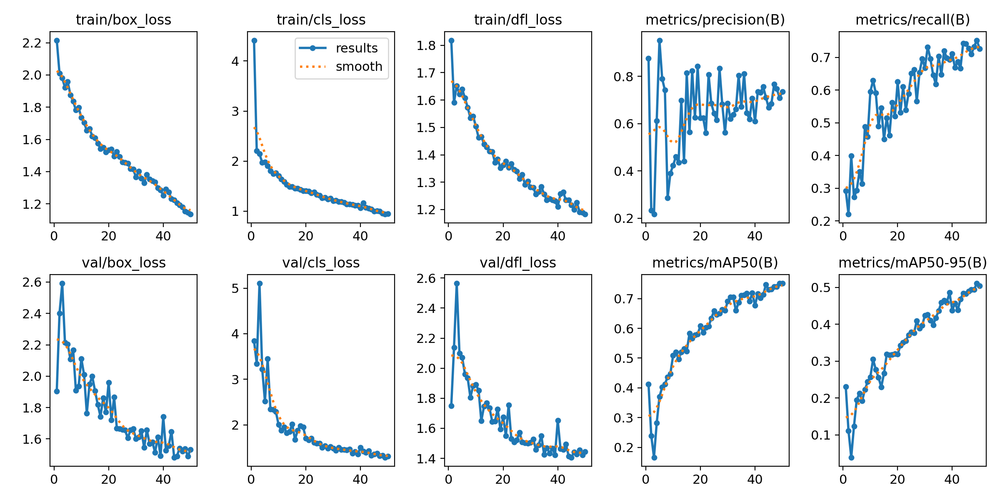


confusion_matrix.png


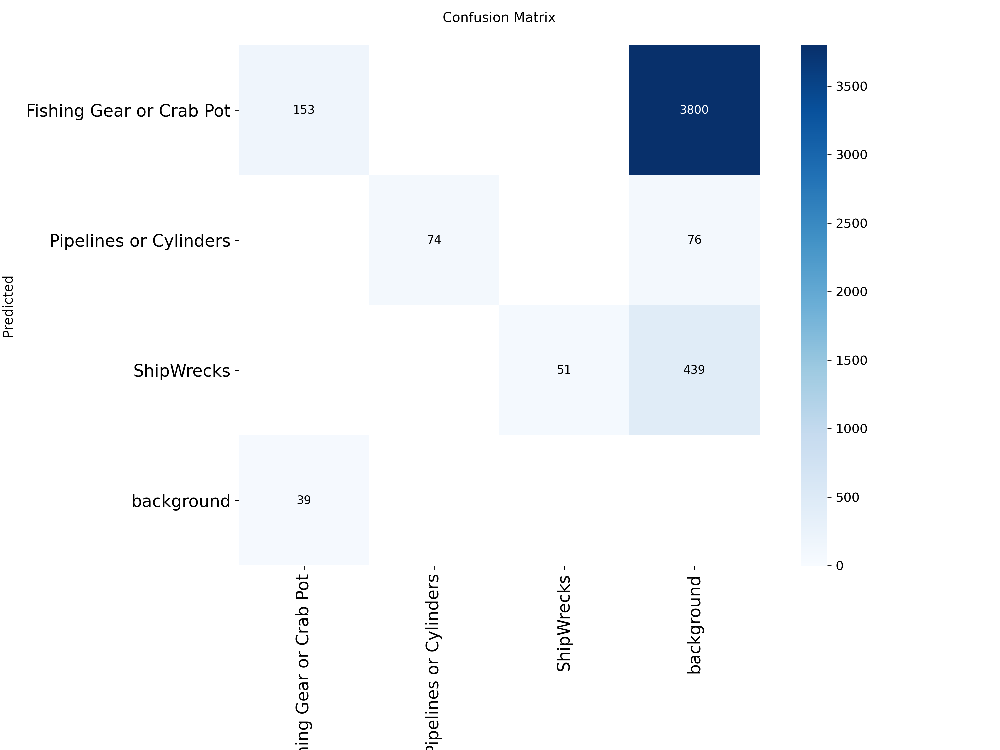


Cell 53 inspection completed.


In [ ]:

# PHASE 6 — CELL 53: Inspect YOLO training history and artifacts

from pathlib import Path
import pandas as pd
from IPython.display import display, Image

YOLO_PHASE6_RUN_DIR = (
    PROJECT_DIR / "runs" / "marine_debris" / "yolov8n_phase6_fresh"
)

# 1. Verify important output files
important_files = [
    YOLO_PHASE6_RUN_DIR / "results.csv",
    YOLO_PHASE6_RUN_DIR / "results.png",
    YOLO_PHASE6_RUN_DIR / "confusion_matrix.png",
    YOLO_PHASE6_RUN_DIR / "weights" / "best.pt",
    YOLO_PHASE6_RUN_DIR / "weights" / "last.pt",
]

print("PHASE 6 ARTIFACT CHECK")
for file_path in important_files:
    print(f"{'FOUND' if file_path.is_file() else 'NOT FOUND'}: {file_path.name}")

assert (YOLO_PHASE6_RUN_DIR / "results.csv").is_file()
assert (YOLO_PHASE6_RUN_DIR / "weights" / "best.pt").is_file()

# 2. Read training history
history = pd.read_csv(YOLO_PHASE6_RUN_DIR / "results.csv")
history.columns = history.columns.str.strip()

print("\nTraining history shape:", history.shape)
print("Number of recorded epochs:", len(history))

# 3. Show the final recorded epochs
print("\nLAST FIVE EPOCHS")
display(history.tail(5).round(4))

# 4. Identify the epoch with the highest recorded validation mAP@50-95
map_column = "metrics/mAP50-95(B)"

if map_column in history.columns:
    best_row_index = history[map_column].idxmax()
    print("\nBEST RECORDED mAP@50-95")
    print("Epoch:", int(best_row_index) + 1)
    print("mAP@50-95:", round(float(history.loc[best_row_index, map_column]), 4))
else:
    print("\nAvailable metric columns:")
    print([c for c in history.columns if "metrics/" in c])

# 5. Display training curves and validation confusion matrix, if available
for plot_name in ["results.png", "confusion_matrix.png"]:
    plot_path = YOLO_PHASE6_RUN_DIR / plot_name
    if plot_path.is_file():
        print(f"\n{plot_name}")
        display(Image(filename=str(plot_path)))
    else:
        print(f"\nPlot not available: {plot_name}")

print("\nCell 53 inspection completed.")


## Phase 7: Model Evaluation

This phase evaluates the trained YOLOv8n model on the held-out test split. It records precision, recall, mAP@50, and mAP@50–95, compares test performance with validation performance, and visualizes predictions against the ground-truth annotations. Qualitative error analysis is used to illustrate selected correct detections, missed objects, and false positives.

The held-out test results are reported separately from validation results. Test data should not be used for model tuning.

In [ ]:

# PHASE 7 — CELL 54: Configure and verify test evaluation

from pathlib import Path
from collections import Counter
import yaml

PROJECT_DIR = Path("/content/drive/MyDrive/dl case study")

CLEAN_DATASET_ROOT = (
    PROJECT_DIR / "datasets" / "SSS-Marine-Debris-Detection.grouped"
)
DATA_YAML = CLEAN_DATASET_ROOT / "data.yaml"

YOLO_PHASE6_RUN_DIR = (
    PROJECT_DIR / "runs" / "marine_debris" / "yolov8n_phase6_fresh"
)
YOLO_BEST_MODEL = YOLO_PHASE6_RUN_DIR / "weights" / "best.pt"

TEST_IMAGES_DIR = CLEAN_DATASET_ROOT / "test" / "images"
TEST_LABELS_DIR = CLEAN_DATASET_ROOT / "test" / "labels"

# Verify paths
assert DATA_YAML.is_file(), f"Dataset YAML missing: {DATA_YAML}"
assert YOLO_BEST_MODEL.is_file(), f"Best checkpoint missing: {YOLO_BEST_MODEL}"
assert TEST_IMAGES_DIR.is_dir(), f"Test images missing: {TEST_IMAGES_DIR}"
assert TEST_LABELS_DIR.is_dir(), f"Test labels missing: {TEST_LABELS_DIR}"

with open(DATA_YAML, "r") as f:
    dataset_config = yaml.safe_load(f)

assert dataset_config["nc"] == 3
assert dataset_config["names"] == [
    "Fishing Gear or Crab Pot",
    "Pipelines or Cylinders",
    "ShipWrecks",
]

test_images = sorted(
    p for p in TEST_IMAGES_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

test_labels = sorted(TEST_LABELS_DIR.glob("*.txt"))

print("PHASE 7 — TEST EVALUATION CONFIGURATION")
print("-" * 45)
print("Best checkpoint:", YOLO_BEST_MODEL)
print("Checkpoint size (MB):", round(YOLO_BEST_MODEL.stat().st_size / (1024**2), 2))
print("Test images:", len(test_images))
print("Test label files:", len(test_labels))
print("Classes:", dataset_config["names"])
print("Test split:", dataset_config["test"])
print("\nConfiguration verification passed.")
print("No test evaluation has been run yet.")


PHASE 7 — TEST EVALUATION CONFIGURATION
---------------------------------------------
Best checkpoint: /content/drive/MyDrive/dl case study/runs/marine_debris/yolov8n_phase6_fresh/weights/best.pt
Checkpoint size (MB): 6.21
Test images: 133
Test label files: 133
Classes: ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks']
Test split: /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/test/images

Configuration verification passed.
No test evaluation has been run yet.


In [ ]:

# PHASE 7 — CELL 55: Formal YOLOv8n test evaluation


from pathlib import Path
import json
import yaml
from ultralytics import YOLO

# --------------------------------------------------
# 1. Paths and dataset configuration
# --------------------------------------------------
PROJECT_DIR = Path("/content/drive/MyDrive/dl case study")

CLEAN_DATASET_ROOT = (
    PROJECT_DIR / "datasets" / "SSS-Marine-Debris-Detection.grouped"
)
DATA_YAML = CLEAN_DATASET_ROOT / "data.yaml"

YOLO_PHASE7_RUN_DIR = (
    PROJECT_DIR / "runs" / "marine_debris" / "phase7_yolo_test"
)
YOLO_PHASE7_RUN_DIR.mkdir(parents=True, exist_ok=True)

YOLO_BEST_MODEL = (
    PROJECT_DIR / "runs" / "marine_debris"
    / "yolov8n_phase6_fresh" / "weights" / "best.pt"
)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
}

assert DATA_YAML.is_file(), f"Dataset YAML missing: {DATA_YAML}"
assert YOLO_BEST_MODEL.is_file(), (
    f"Trained YOLO checkpoint missing: {YOLO_BEST_MODEL}"
)

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

class_names = data_config["names"]
if isinstance(class_names, dict):
    class_names = [
        class_names[k] for k in sorted(class_names, key=lambda x: int(x))
    ]

# Resolve the test image directory from the dataset YAML.
yaml_root = Path(data_config.get("path", CLEAN_DATASET_ROOT))
if not yaml_root.is_absolute():
    yaml_root = (DATA_YAML.parent / yaml_root).resolve()

test_path = Path(data_config["test"])
if not test_path.is_absolute():
    test_path = (yaml_root / test_path).resolve()

test_label_dir = test_path.parent / "labels"

assert test_path.is_dir(), f"Test images directory missing: {test_path}"
assert test_label_dir.is_dir(), (
    f"Test labels directory missing: {test_label_dir}"
)

test_images = sorted(
    p for p in test_path.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

if not test_images:
    raise ValueError(f"No test images found in {test_path}")

# --------------------------------------------------
# 2. Calculate real test-set counts and validate labels
# --------------------------------------------------
test_annotated_objects = 0
empty_label_images = 0
image_stems = {p.stem for p in test_images}
label_stems = {p.stem for p in test_label_dir.glob("*.txt")}

if image_stems != label_stems:
    raise ValueError(
        "Test image-label mismatch: "
        f"{len(image_stems - label_stems)} images lack labels; "
        f"{len(label_stems - image_stems)} labels lack matching images."
    )

for image_path in test_images:
    label_path = test_label_dir / f"{image_path.stem}.txt"
    lines = [
        line.strip()
        for line in label_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]

    if not lines:
        empty_label_images += 1

    for line in lines:
        parts = line.split()
        if len(parts) != 5:
            raise ValueError(
                f"Invalid YOLO annotation in {label_path}: {line}"
            )

        class_id = int(parts[0])
        if not 0 <= class_id < len(class_names):
            raise ValueError(
                f"Invalid class ID {class_id} in {label_path}"
            )

        test_annotated_objects += 1

print("Actual grouped test-set statistics")
print("Test images:", len(test_images))
print("Annotated objects:", test_annotated_objects)
print("Empty/background images:", empty_label_images)
print("Classes:", class_names)

# --------------------------------------------------
# 3. Evaluate the saved model on the test split
# --------------------------------------------------
yolo_test_model = YOLO(str(YOLO_BEST_MODEL))

test_metrics = yolo_test_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project=str(YOLO_PHASE7_RUN_DIR),
    name="yolov8n_test_evaluation",
    exist_ok=True,
    verbose=True,
)

# --------------------------------------------------
# 4. Save metrics using Cell 59's expected JSON keys
# --------------------------------------------------
results_summary = {
    "model": "YOLOv8n",
    "checkpoint": str(YOLO_BEST_MODEL),
    "evaluation_split": "test",
    "test_images": len(test_images),
    "test_annotated_objects": test_annotated_objects,
    "empty_label_images": empty_label_images,
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50),
    "mAP50_95": float(test_metrics.box.map),
    "per_class_mAP50": [
        float(value) for value in test_metrics.box.ap50
    ],
    "per_class_mAP50_95": [
        float(value) for value in test_metrics.box.ap
    ],
    "class_names": list(class_names),
}

summary_path = (
    YOLO_PHASE7_RUN_DIR / "yolov8n_test_metrics.json"
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(results_summary, f, indent=2)

print("\nYOLOv8n HELD-OUT TEST RESULTS")
print("-" * 45)
print(f"Test images:   {results_summary['test_images']}")
print(f"GT objects:    {results_summary['test_annotated_objects']}")
print(f"Precision:     {results_summary['precision']:.4f}")
print(f"Recall:        {results_summary['recall']:.4f}")
print(f"mAP@50:        {results_summary['mAP50']:.4f}")
print(f"mAP@50–95:     {results_summary['mAP50_95']:.4f}")

print("\nPer-class results:")
for name, ap50, ap5095 in zip(
    results_summary["class_names"],
    results_summary["per_class_mAP50"],
    results_summary["per_class_mAP50_95"],
):
    print(f"{name}: mAP@50={ap50:.4f}, mAP@50–95={ap5095:.4f}")

print("\nMetrics saved to:", summary_path)
print("Evaluation output directory:", test_metrics.save_dir)


Actual grouped test-set statistics
Test images: 133
Annotated objects: 153
Empty/background images: 17
Classes: ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks']
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 9.3±19.4 ms, read: 42.2±41.6 MB/s, size: 81.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/dl case study/datasets/SSS-Marine-Debris-Detection.grouped/test/labels.cache... 133 images, 17 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 133/133 26.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.7it/s 3.3s
                   all        133        153      0.714      0.706      0.735      0.471
Fishing

## Phase 7.1: Image-Level Target-Presence / Anomaly Screening

This additional evaluation converts the trained YOLOv8n detector's predictions into an image-level decision: an image is flagged if at least one detection exceeds a fixed confidence threshold. Ground-truth images with one or more annotated objects are considered target-present; images with empty labels are considered target-absent/background. This is a **proxy for screening known target classes**, not open-set anomaly detection for unknown objects. The confidence threshold is fixed before reviewing test results; any threshold optimization should be performed on validation data only.

In [ ]:
# PHASE 7 — ADDITIONAL CELL: Image-level target-presence screening
# Uses the existing trained YOLOv8n checkpoint. Does not retrain or tune on test data.

from pathlib import Path
import json
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from ultralytics import YOLO

# Predeclare this operating threshold. If you later tune it, use validation data only.
IMAGE_SCREEN_CONF = 0.25
IMAGE_SCREEN_IMGSZ = 640
screen_model = YOLO(str(YOLO_BEST_MODEL))
image_screen_rows = []

for image_path in test_images:
    label_path = TEST_LABELS_DIR / f"{image_path.stem}.txt"
    if not label_path.is_file():
        raise FileNotFoundError(f"Missing label file: {label_path}")
    gt_lines = [line.strip() for line in label_path.read_text().splitlines() if line.strip()]
    gt_target_present = int(len(gt_lines) > 0)

    pred = screen_model.predict(
        source=str(image_path), imgsz=IMAGE_SCREEN_IMGSZ,
        conf=IMAGE_SCREEN_CONF, device=0, verbose=False
    )[0]
    detection_count = 0 if pred.boxes is None else len(pred.boxes)
    predicted_target_present = int(detection_count > 0)

    image_screen_rows.append({
        "image": image_path.name,
        "ground_truth_target_present": gt_target_present,
        "predicted_target_present": predicted_target_present,
        "ground_truth_objects": len(gt_lines),
        "detections_above_threshold": detection_count,
        "confidence_threshold": IMAGE_SCREEN_CONF,
    })

image_screen_df = pd.DataFrame(image_screen_rows)
y_img_true = image_screen_df["ground_truth_target_present"].to_numpy()
y_img_pred = image_screen_df["predicted_target_present"].to_numpy()
cm_img = confusion_matrix(y_img_true, y_img_pred, labels=[0, 1])
tn, fp, fn, tp = cm_img.ravel()
empty_mask = image_screen_df["ground_truth_target_present"] == 0
empty_count = int(empty_mask.sum())
false_alarm_count = int(((image_screen_df["ground_truth_target_present"] == 0) & (image_screen_df["predicted_target_present"] == 1)).sum())

image_screen_results = {
    "task": "image-level known-target presence screening (proxy; not open-set anomaly detection)",
    "evaluation_split": "test",
    "confidence_threshold": IMAGE_SCREEN_CONF,
    "test_images": int(len(image_screen_df)),
    "ground_truth_target_present_images": int(y_img_true.sum()),
    "ground_truth_empty_background_images": empty_count,
    "true_positive_images": int(tp),
    "true_negative_images": int(tn),
    "false_positive_images": int(fp),
    "false_negative_images": int(fn),
    "image_level_accuracy": float(accuracy_score(y_img_true, y_img_pred)),
    "image_level_precision": float(precision_score(y_img_true, y_img_pred, zero_division=0)),
    "image_level_recall": float(recall_score(y_img_true, y_img_pred, zero_division=0)),
    "image_level_f1": float(f1_score(y_img_true, y_img_pred, zero_division=0)),
    "false_alarm_rate_on_empty_images": float(false_alarm_count / empty_count) if empty_count else None,
    "false_alarm_count_on_empty_images": false_alarm_count,
    "confusion_matrix_labels": ["background/empty", "target-present"],
    "confusion_matrix": cm_img.tolist(),
}

ANOMALY_RESULTS_DIR = PROJECT_DIR / "runs" / "marine_debris" / "phase7_yolo_test"
ANOMALY_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
image_screen_csv = ANOMALY_RESULTS_DIR / "image_level_target_screening.csv"
image_screen_json = ANOMALY_RESULTS_DIR / "image_level_target_screening.json"
image_screen_df.to_csv(image_screen_csv, index=False)
with open(image_screen_json, "w", encoding="utf-8") as f:
    json.dump(image_screen_results, f, indent=2)

print("IMAGE-LEVEL TARGET-PRESENCE SCREENING")
print("This is known-class target-presence screening, not open-set anomaly detection.")
print(f"Images: {len(image_screen_df)} | Empty/background images: {empty_count}")
print(f"Threshold: {IMAGE_SCREEN_CONF:.2f}")
print(f"TP={tp}, TN={tn}, FP={fp}, FN={fn}")
print(f"Image-level accuracy: {image_screen_results['image_level_accuracy']:.4f}")
print(f"Image-level precision: {image_screen_results['image_level_precision']:.4f}")
print(f"Image-level recall: {image_screen_results['image_level_recall']:.4f}")
print(f"Image-level F1: {image_screen_results['image_level_f1']:.4f}")
if image_screen_results["false_alarm_rate_on_empty_images"] is not None:
    print(f"False-alarm rate on empty images: {image_screen_results['false_alarm_rate_on_empty_images']:.4f} ({false_alarm_count}/{empty_count})")
print("\nImage-level classification report:")
print(classification_report(y_img_true, y_img_pred, labels=[0, 1], target_names=["background/empty", "target-present"], digits=4, zero_division=0))
print("Saved:", image_screen_csv)
print("Saved:", image_screen_json)


IMAGE-LEVEL TARGET-PRESENCE SCREENING
This is known-class target-presence screening, not open-set anomaly detection.
Images: 133 | Empty/background images: 17
Threshold: 0.25
TP=89, TN=15, FP=2, FN=27
Image-level accuracy: 0.7820
Image-level precision: 0.9780
Image-level recall: 0.7672
Image-level F1: 0.8599
False-alarm rate on empty images: 0.1176 (2/17)

Image-level classification report:
                  precision    recall  f1-score   support

background/empty     0.3571    0.8824    0.5085        17
  target-present     0.9780    0.7672    0.8599       116

        accuracy                         0.7820       133
       macro avg     0.6676    0.8248    0.6842       133
    weighted avg     0.8987    0.7820    0.8150       133

Saved: /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/image_level_target_screening.csv
Saved: /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/image_level_target_screening.json


In [ ]:

# PHASE 7 — CELL 56: Compare validation and test performance

import pandas as pd
from pathlib import Path

PHASE6_RESULTS_CSV = (
    PROJECT_DIR / "runs" / "marine_debris"
    / "yolov8n_phase6_fresh" / "results.csv"
)

PHASE7_METRICS_JSON = (
    PROJECT_DIR / "runs" / "marine_debris"
    / "phase7_yolo_test" / "yolov8n_test_metrics.json"
)

import json

assert PHASE6_RESULTS_CSV.is_file()
assert PHASE7_METRICS_JSON.is_file()

# Best validation epoch from the recorded training history
history = pd.read_csv(PHASE6_RESULTS_CSV)
best_epoch_idx = history["metrics/mAP50-95(B)"].idxmax()
best_epoch = history.loc[best_epoch_idx]

with open(PHASE7_METRICS_JSON, "r") as f:
    test_summary = json.load(f)

comparison = pd.DataFrame([
    {
        "Metric": "Precision",
        "Validation": float(best_epoch["metrics/precision(B)"]),
        "Test": test_summary["precision"],
    },
    {
        "Metric": "Recall",
        "Validation": float(best_epoch["metrics/recall(B)"]),
        "Test": test_summary["recall"],
    },
    {
        "Metric": "mAP@50",
        "Validation": float(best_epoch["metrics/mAP50(B)"]),
        "Test": test_summary["mAP50"],
    },
    {
        "Metric": "mAP@50–95",
        "Validation": float(best_epoch["metrics/mAP50-95(B)"]),
        "Test": test_summary["mAP50_95"],
    },
])

comparison["Difference (Test - Val)"] = (
    comparison["Test"] - comparison["Validation"]
)

print(f"Best validation epoch: {int(best_epoch['epoch']) + 1}")
print("\nValidation vs. held-out test performance")
display(comparison.round(4))

comparison_path = (
    PROJECT_DIR / "runs" / "marine_debris"
    / "phase7_yolo_test" / "validation_test_comparison.csv"
)
comparison.to_csv(comparison_path, index=False)

print("\nComparison saved to:", comparison_path)
print(
    "\nInterpretation: these are overall metrics. "
    "Class-level results should also be considered."
)


Best validation epoch: 50

Validation vs. held-out test performance


,Metric,Validation,Test,Difference (Test - Val)
0,Precision,0.7087,0.7140,0.0053
1,Recall,0.7526,0.7057,-0.0468
2,mAP@50,0.7510,0.7348,-0.0162
3,mAP@50–95,0.5108,0.4707,-0.0402



Comparison saved to: /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/validation_test_comparison.csv

Interpretation: these are overall metrics. Class-level results should also be considered.


Generating predictions for 6 test images.
Output directory: /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/test_predictions
Results saved to /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/test_predictions/visualizations
Results saved to /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/test_predictions/visualizations
Results saved to /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/test_predictions/visualizations
Results saved to /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/test_predictions/visualizations
Results saved to /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/test_predictions/visualizations
Results saved to /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/test_predictions/visualizations

Prediction visualizations saved.
Saved prediction images: 6

Image: 000227_jpg.rf.1f251622eceb4fc5ffabfd7e91411db0.jp

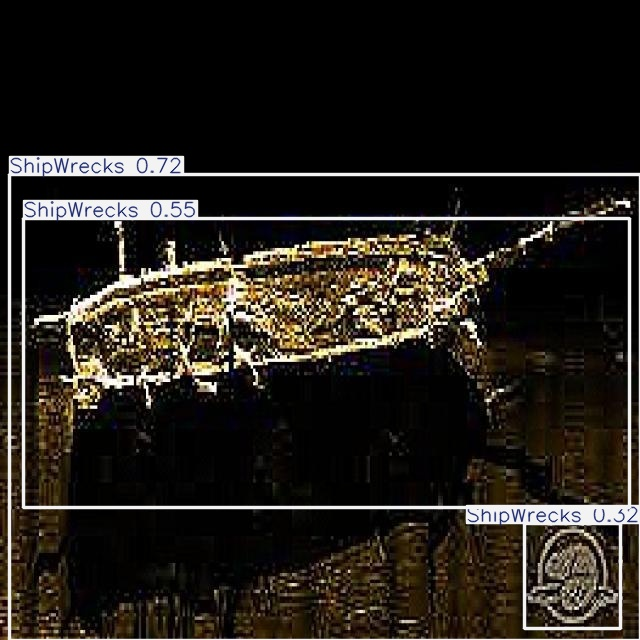


Image: BC_POST_T2_02_00_2_7_png_jpg.rf.fa5a0b25187da1db3896cf587445cb05.jpg


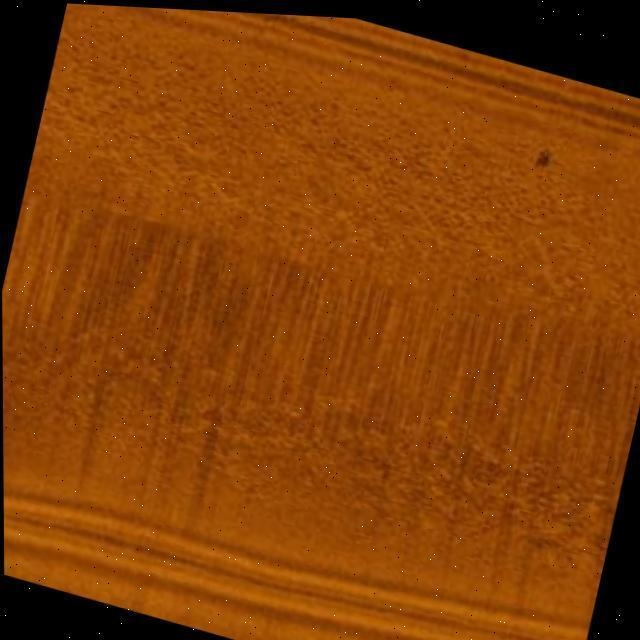


Image: Contact_323_sslo_png_jpg.rf.42167c57e3af7af59e3ad63e7777c3cb.jpg


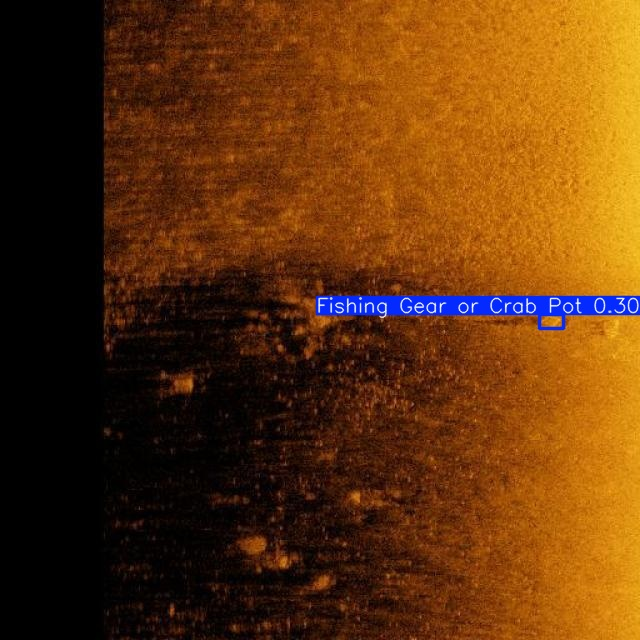


Image: HF_1693569529-810_jpg.rf.aa9e74f6d61874a4a59c7fc09946ae9e.jpg


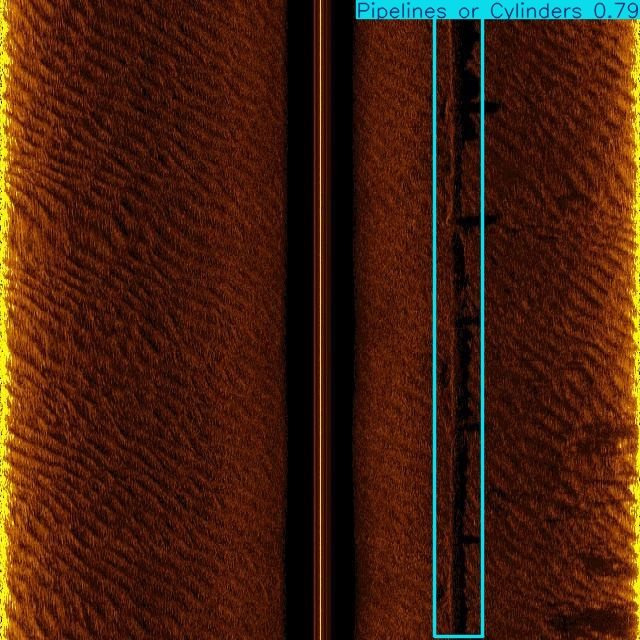


Image: HF_1693569563-809_jpg.rf.6624e5da32d8dcf302f95e7353a7f9b0.jpg


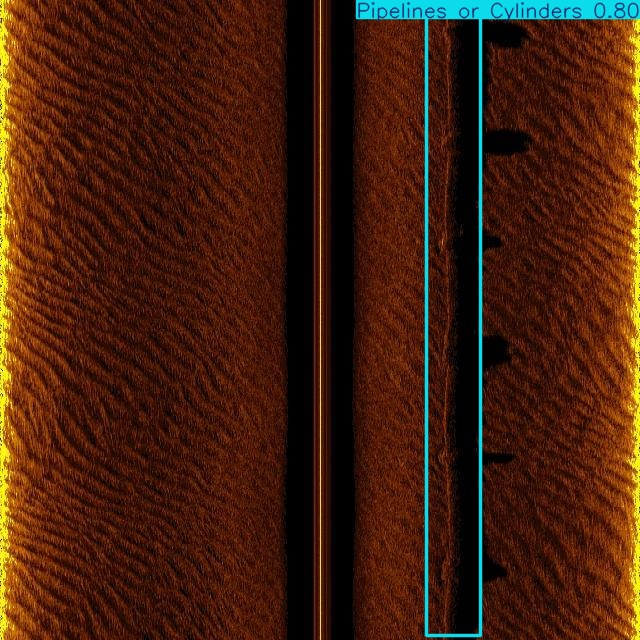


Image: LF_1693569444-790_jpg.rf.88cebe44eae0c0d3d447323ac520d23c.jpg


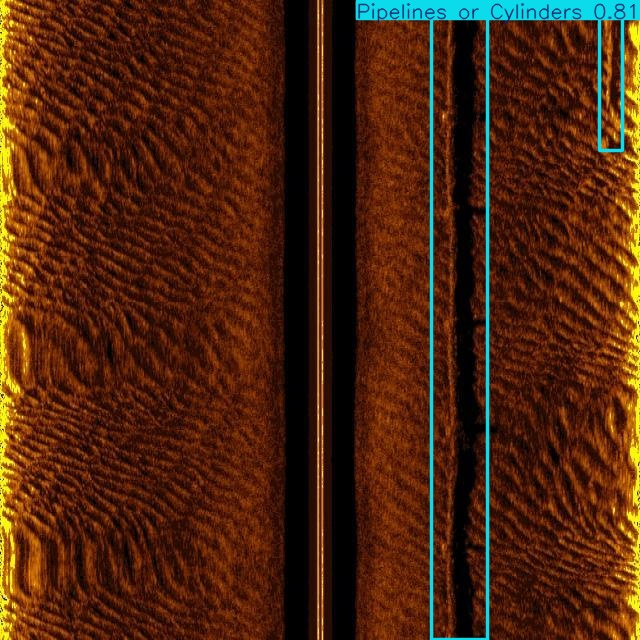

In [ ]:

# PHASE 7 — CELL 57: Visualize YOLO predictions on test images

from pathlib import Path
from IPython.display import display, Image
import random

# Reproducible sample selection
random.seed(SEED)

test_image_paths = sorted([
    p for p in TEST_IMAGES_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
])

assert len(test_image_paths) > 0, "No test images found."

sample_count = min(6, len(test_image_paths))
sample_images = random.sample(test_image_paths, sample_count)

PREDICTION_DIR = (
    PROJECT_DIR / "runs" / "marine_debris"
    / "phase7_yolo_test" / "test_predictions"
)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

print("Generating predictions for", sample_count, "test images.")
print("Output directory:", PREDICTION_DIR)

# Load the saved best model if it is not already loaded
from ultralytics import YOLO
prediction_model = YOLO(str(YOLO_BEST_MODEL))

for image_path in sample_images:
    prediction_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        save=True,
        project=str(PREDICTION_DIR),
        name="visualizations",
        exist_ok=True,
        verbose=False,
    )

print("\nPrediction visualizations saved.")

visualization_dir = PREDICTION_DIR / "visualizations"
saved_images = sorted([
    p for p in visualization_dir.iterdir()
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
]) if visualization_dir.is_dir() else []

print("Saved prediction images:", len(saved_images))

for image_path in saved_images[:6]:
    print("\nImage:", image_path.name)
    display(Image(filename=str(image_path)))


In [ ]:

# PHASE 7 — CELL 58: Compare YOLO predictions with ground truth

from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import cv2
from IPython.display import display

# Reuse the exact six images selected in Cell 57.
assert "sample_images" in globals() and len(sample_images) > 0
assert "prediction_model" in globals()

CLASS_NAMES = [
    "Fishing Gear or Crab Pot",
    "Pipelines or Cylinders",
    "ShipWrecks",
]

IOU_THRESHOLD = 0.50
CONF_THRESHOLD = 0.25

def calculate_iou(box_a, box_b):
    """Calculate IoU for two boxes in xyxy format."""
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)

    area_a = max(0.0, box_a[2] - box_a[0]) * max(
        0.0, box_a[3] - box_a[1]
    )
    area_b = max(0.0, box_b[2] - box_b[0]) * max(
        0.0, box_b[3] - box_b[1]
    )

    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def load_ground_truth(label_path):
    """Read YOLO labels: class_id, x_center, y_center, width, height."""
    if not label_path.is_file():
        raise FileNotFoundError(f"Missing label file: {label_path}")

    rows = []
    with open(label_path, "r") as f:
        for line_number, line in enumerate(f, start=1):
            parts = line.strip().split()
            if not parts:
                continue
            if len(parts) != 5:
                raise ValueError(
                    f"Invalid label format in {label_path}, line {line_number}"
                )

            class_id = int(parts[0])
            xc, yc, w, h = map(float, parts[1:])

            rows.append((class_id, xc, yc, w, h))

    return rows


analysis_rows = []

for image_path in sample_images:
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image_height, image_width = image.shape[:2]
    label_path = TEST_LABELS_DIR / f"{image_path.stem}.txt"

    # Convert ground-truth boxes to pixel xyxy coordinates.
    gt_boxes = []
    for class_id, xc, yc, w, h in load_ground_truth(label_path):
        x1 = (xc - w / 2) * image_width
        y1 = (yc - h / 2) * image_height
        x2 = (xc + w / 2) * image_width
        y2 = (yc + h / 2) * image_height
        gt_boxes.append({
            "class_id": class_id,
            "box": [x1, y1, x2, y2],
        })

    # Inference on the original test image.
    prediction = prediction_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=CONF_THRESHOLD,
        device=0,
        verbose=False,
    )[0]

    pred_boxes = []
    if prediction.boxes is not None:
        for box in prediction.boxes:
            pred_boxes.append({
                "class_id": int(box.cls.item()),
                "confidence": float(box.conf.item()),
                "box": box.xyxy[0].cpu().numpy().tolist(),
            })

    # Greedy matching by descending IoU, with class agreement required.
    candidates = []
    for gt_index, gt in enumerate(gt_boxes):
        for pred_index, pred in enumerate(pred_boxes):
            if gt["class_id"] != pred["class_id"]:
                continue

            iou = calculate_iou(gt["box"], pred["box"])
            if iou >= IOU_THRESHOLD:
                candidates.append((iou, gt_index, pred_index))

    candidates.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()
    matched_ious = []

    for iou, gt_index, pred_index in candidates:
        if gt_index in matched_gt or pred_index in matched_pred:
            continue
        matched_gt.add(gt_index)
        matched_pred.add(pred_index)
        matched_ious.append(iou)

    missed_gt = len(gt_boxes) - len(matched_gt)
    false_positives = len(pred_boxes) - len(matched_pred)

    analysis_rows.append({
        "Image": image_path.name,
        "GT objects": len(gt_boxes),
        "Predictions": len(pred_boxes),
        "Correct matches": len(matched_gt),
        "Missed GT": missed_gt,
        "False positives": false_positives,
        "Mean matched IoU": (
            round(float(np.mean(matched_ious)), 3)
            if matched_ious else np.nan
        ),
        "GT classes": ", ".join(
            CLASS_NAMES[g["class_id"]] for g in gt_boxes
        ) if gt_boxes else "Background",
        "Predicted classes": ", ".join(
            CLASS_NAMES[p["class_id"]] for p in pred_boxes
        ) if pred_boxes else "No detections",
    })

analysis_df = pd.DataFrame(analysis_rows)

print("SIX-IMAGE GROUND-TRUTH COMPARISON")
display(analysis_df)

print("\nAGGREGATE COUNTS FOR THESE SIX IMAGES")
print("Ground-truth objects:", int(analysis_df["GT objects"].sum()))
print("Predictions:", int(analysis_df["Predictions"].sum()))
print("Correct matches:", int(analysis_df["Correct matches"].sum()))
print("Missed ground-truth objects:", int(analysis_df["Missed GT"].sum()))
print("False-positive predictions:", int(analysis_df["False positives"].sum()))

ERROR_ANALYSIS_PATH = (
    PROJECT_DIR / "runs" / "marine_debris"
    / "phase7_yolo_test" / "six_image_error_analysis.csv"
)
analysis_df.to_csv(ERROR_ANALYSIS_PATH, index=False)

print("\nError analysis saved to:", ERROR_ANALYSIS_PATH)
print(
    "\nNote: this is a small qualitative sample, not a replacement "
    "for full-test-set metrics."
)


SIX-IMAGE GROUND-TRUTH COMPARISON


,Image,GT objects,Predictions,Correct matches,Missed GT,False positives,Mean matched IoU,GT classes,Predicted classes
0,BC_POST_T2_02_00_2_7_png_jpg.rf.fa5a0b25187da1...,0,0,0,0,0,NaN,Background,No detections
1,000227_jpg.rf.1f251622eceb4fc5ffabfd7e91411db0...,1,3,1,0,2,0.614,ShipWrecks,"ShipWrecks, ShipWrecks, ShipWrecks"
2,LF_1693569444-790_jpg.rf.88cebe44eae0c0d3d4473...,2,2,2,0,0,0.793,"Pipelines or Cylinders, Pipelines or Cylinders","Pipelines or Cylinders, Pipelines or Cylinders"
3,HF_1693569563-809_jpg.rf.6624e5da32d8dcf302f95...,1,1,1,0,0,0.805,Pipelines or Cylinders,Pipelines or Cylinders
4,HF_1693569529-810_jpg.rf.aa9e74f6d61874a4a59c7...,1,1,1,0,0,0.881,Pipelines or Cylinders,Pipelines or Cylinders
5,Contact_323_sslo_png_jpg.rf.42167c57e3af7af59e...,3,1,1,2,0,0.781,"Fishing Gear or Crab Pot, Fishing Gear or Crab...",Fishing Gear or Crab Pot



AGGREGATE COUNTS FOR THESE SIX IMAGES
Ground-truth objects: 8
Predictions: 8
Correct matches: 6
Missed ground-truth objects: 2
False-positive predictions: 2

Error analysis saved to: /content/drive/MyDrive/dl case study/runs/marine_debris/phase7_yolo_test/six_image_error_analysis.csv

Note: this is a small qualitative sample, not a replacement for full-test-set metrics.


## Phase 8: Results, Visualizations, and Conclusion

This phase consolidates the dataset statistics and model evaluation results into structured experiment summaries and a final case-study report. It documents CNN validation and held-out test crop-classification results, YOLOv8n object-detection results, and image-level known-target presence screening. It presents the main findings and limitations and summarizes possible directions for improving marine-debris detection from side-scan sonar imagery.

CNN validation/test classification metrics and YOLO held-out test detection metrics represent different tasks and must not be interpreted as direct, like-for-like performance comparisons. Image-level target-presence screening is a limited proxy and is not open-set anomaly detection.

In [ ]:

# PHASE 8 — CELL 59: Consolidate experimental results from saved files

from pathlib import Path
from collections import Counter
import json
import pandas as pd
import yaml

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------
PROJECT_DIR = Path("/content/drive/MyDrive/dl case study")

RESULTS_DIR = PROJECT_DIR / "runs" / "marine_debris"
CNN_DIR = RESULTS_DIR / "cnn_baseline"
PHASE6_DIR = RESULTS_DIR / "yolov8n_phase6_fresh"
PHASE7_DIR = RESULTS_DIR / "phase7_yolo_test"
PHASE8_DIR = RESULTS_DIR / "phase8_final_report"

PHASE8_DIR.mkdir(parents=True, exist_ok=True)

GROUPED_DATASET_DIR = (
    PROJECT_DIR / "datasets" / "SSS-Marine-Debris-Detection.grouped"
)
GROUPED_YAML = GROUPED_DATASET_DIR / "data.yaml"

CNN_VALIDATION_JSON = CNN_DIR / "validation_results.json"
CNN_TEST_JSON = CNN_DIR / "test_results.json"
YOLO_TEST_JSON = PHASE7_DIR / "yolov8n_test_metrics.json"
SCREENING_JSON = PHASE7_DIR / "image_level_target_screening.json"

# --------------------------------------------------
# 2. Validate required files
# --------------------------------------------------
required_files = {
    "Grouped dataset YAML": GROUPED_YAML,
    "CNN validation metrics": CNN_VALIDATION_JSON,
    "YOLO test metrics": YOLO_TEST_JSON,
}

for description, path in required_files.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"{description} not found:\n{path}\n"
            "Run the corresponding earlier phase successfully first."
        )

with open(GROUPED_YAML, "r") as f:
    dataset_config = yaml.safe_load(f)

with open(CNN_VALIDATION_JSON, "r") as f:
    cnn_val_raw = json.load(f)

with open(YOLO_TEST_JSON, "r") as f:
    yolo_test = json.load(f)

# Optional evaluations: include only when their JSON files exist.
cnn_test_results = None
image_screen_results = None

if CNN_TEST_JSON.is_file():
    with open(CNN_TEST_JSON, "r") as f:
        cnn_test_results = json.load(f)

if SCREENING_JSON.is_file():
    with open(SCREENING_JSON, "r") as f:
        image_screen_results = json.load(f)

# --------------------------------------------------
# 3. Calculate dataset statistics from actual files
# --------------------------------------------------
class_names = dataset_config.get("names", [])
if isinstance(class_names, dict):
    class_names = [
        class_names[k] for k in sorted(class_names, key=lambda x: int(x))
    ]

dataset_stats = {
    "total_images": 0,
    "annotated_objects": 0,
    "classes": class_names,
    "train_images": 0,
    "validation_images": 0,
    "test_images": 0,
    "split_object_counts": {},
    "empty_label_images": {},
}

split_mapping = {
    "train": "train_images",
    "valid": "validation_images",
    "test": "test_images",
}

for split in ["train", "valid", "test"]:
    image_dir = GROUPED_DATASET_DIR / split / "images"
    label_dir = GROUPED_DATASET_DIR / split / "labels"

    if not image_dir.is_dir() or not label_dir.is_dir():
        raise FileNotFoundError(
            f"Missing grouped dataset images or labels for split: {split}"
        )

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
        }
    ]

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in label_dir.glob("*.txt")}

    if image_stems != label_stems:
        raise ValueError(
            f"Image-label mismatch in {split}: "
            f"{len(image_stems - label_stems)} missing labels, "
            f"{len(label_stems - image_stems)} labels without images."
        )

    object_counts = Counter()
    empty_labels = 0

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"
        lines = [
            line.strip()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            empty_labels += 1

        for line in lines:
            parts = line.split()
            if len(parts) != 5:
                raise ValueError(
                    f"Invalid YOLO annotation in {label_path}: {line}"
                )

            class_id = int(parts[0])
            if not 0 <= class_id < len(class_names):
                raise ValueError(
                    f"Unexpected class ID {class_id} in {label_path}"
                )

            object_counts[class_id] += 1

    dataset_stats[split_mapping[split]] = len(images)
    dataset_stats["total_images"] += len(images)
    dataset_stats["annotated_objects"] += sum(object_counts.values())
    dataset_stats["split_object_counts"][split] = {
        class_names[class_id]: count
        for class_id, count in sorted(object_counts.items())
    }
    dataset_stats["empty_label_images"][split] = empty_labels

# --------------------------------------------------
# 4. Extract CNN validation metrics from JSON
# --------------------------------------------------
report = cnn_val_raw.get("classification_report", {})

macro_f1 = report.get("macro avg", {}).get("f1-score")
weighted_f1 = report.get("weighted avg", {}).get("f1-score")

if macro_f1 is None or weighted_f1 is None:
    raise KeyError(
        "CNN validation JSON is missing macro/weighted F1 in "
        "'classification_report'. Check validation_results.json."
    )

cnn_validation = {
    "model": "MarineDebrisCNN",
    "evaluation_split": "validation",
    "best_epoch": cnn_val_raw.get("best_epoch"),
    "validation_accuracy": cnn_val_raw.get("validation_accuracy"),
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "validation_loss": cnn_val_raw.get("best_validation_loss"),
    "validation_samples": cnn_val_raw.get("validation_samples"),
    "note": (
        "Crop-classification metrics; not directly comparable "
        "to YOLO full-image object-detection metrics."
    ),
}

# --------------------------------------------------
# 5. Validate YOLO test results against dataset counts
# --------------------------------------------------
if yolo_test.get("evaluation_split") != "test":
    raise ValueError(
        "YOLO metrics JSON does not identify the evaluation split as test."
    )

if yolo_test.get("test_images") != dataset_stats["test_images"]:
    raise ValueError(
        "YOLO metrics test-image count does not match the current grouped "
        f"dataset: metrics={yolo_test.get('test_images')}, "
        f"dataset={dataset_stats['test_images']}. "
        "Check that the model was evaluated on this dataset version."
    )

if yolo_test.get("test_annotated_objects") != sum(
    dataset_stats["split_object_counts"]["test"].values()
):
    raise ValueError(
        "YOLO metrics annotated-object count does not match the current "
        "grouped test split. Recheck which dataset was evaluated."
    )

# --------------------------------------------------
# 6. Build summary using loaded results
# --------------------------------------------------
experiment_summary = {
    "case_study": (
        "AI-Powered Automated Underwater Marine Debris and "
        "Anomaly Detection System using Side-Scan Sonar Imagery"
    ),
    "dataset": dataset_stats,
    "cnn_classification_baseline": cnn_validation,
    "cnn_test_classification": cnn_test_results,
    "image_level_target_screening": image_screen_results,
    "yolov8n_object_detection": {
        "evaluation_split": yolo_test["evaluation_split"],
        "test_images": yolo_test["test_images"],
        "test_annotated_objects": yolo_test["test_annotated_objects"],
        "precision": yolo_test["precision"],
        "recall": yolo_test["recall"],
        "mAP50": yolo_test["mAP50"],
        "mAP50_95": yolo_test["mAP50_95"],
        "per_class_mAP50": dict(zip(
            yolo_test["class_names"],
            yolo_test["per_class_mAP50"],
        )),
        "per_class_mAP50_95": dict(zip(
            yolo_test["class_names"],
            yolo_test["per_class_mAP50_95"],
        )),
    },
}

# --------------------------------------------------
# 7. Save JSON and CSV
# --------------------------------------------------
summary_json_path = PHASE8_DIR / "experiment_summary.json"
summary_csv_path = PHASE8_DIR / "experiment_summary.csv"

with open(summary_json_path, "w") as f:
    json.dump(experiment_summary, f, indent=2)

summary_rows = [
    {
        "Experiment": "CNN crop classification",
        "Split": "Validation",
        "Metric": "Accuracy",
        "Value": cnn_validation["validation_accuracy"],
    },
    {
        "Experiment": "CNN crop classification",
        "Split": "Validation",
        "Metric": "Macro F1",
        "Value": cnn_validation["macro_f1"],
    },
    {
        "Experiment": "CNN crop classification",
        "Split": "Validation",
        "Metric": "Weighted F1",
        "Value": cnn_validation["weighted_f1"],
    },
]

if cnn_test_results is not None:
    for metric in ["accuracy", "macro_f1", "weighted_f1"]:
        if metric in cnn_test_results:
            summary_rows.append({
                "Experiment": "CNN crop classification",
                "Split": "Held-out test",
                "Metric": metric,
                "Value": cnn_test_results[metric],
            })

for metric in ["precision", "recall", "mAP50", "mAP50_95"]:
    summary_rows.append({
        "Experiment": "YOLOv8n object detection",
        "Split": "Held-out test",
        "Metric": metric,
        "Value": yolo_test[metric],
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(summary_csv_path, index=False)

# --------------------------------------------------
# 8. Print the verified summary
# --------------------------------------------------
print("PHASE 8 — EXPERIMENT SUMMARY")
print("=" * 50)

print("\nDataset counts (read from grouped dataset):")
print(f"Total images:       {dataset_stats['total_images']}")
print(f"Training images:    {dataset_stats['train_images']}")
print(f"Validation images:  {dataset_stats['validation_images']}")
print(f"Test images:        {dataset_stats['test_images']}")
print(f"Annotated objects:  {dataset_stats['annotated_objects']}")
print(f"Classes:            {dataset_stats['classes']}")

print("\nCNN validation results (read from JSON):")
print(f"Best epoch:     {cnn_validation['best_epoch']}")
print(f"Accuracy:       {cnn_validation['validation_accuracy']:.4f}")
print(f"Macro F1:       {cnn_validation['macro_f1']:.4f}")
print(f"Weighted F1:    {cnn_validation['weighted_f1']:.4f}")
print(f"Validation loss:{cnn_validation['validation_loss']}")

print("\nYOLOv8n held-out test results (read from JSON):")
print(f"Precision:      {yolo_test['precision']:.4f}")
print(f"Recall:         {yolo_test['recall']:.4f}")
print(f"mAP@50:         {yolo_test['mAP50']:.4f}")
print(f"mAP@50–95:      {yolo_test['mAP50_95']:.4f}")

print("\nOptional evaluations:")
print("CNN test results:", "loaded" if cnn_test_results is not None else "not found")
print(
    "Image-level screening:",
    "loaded" if image_screen_results is not None else "not found"
)

print("\nSaved files:")
print(summary_json_path)
print(summary_csv_path)

print(
    "\nNote: CNN crop-classification metrics and YOLO object-detection "
    "metrics measure different tasks and must not be directly compared."
)
print(
    "Image-level target-presence screening is a known-class proxy, "
    "not open-set anomaly detection."
)


PHASE 8 — EXPERIMENT SUMMARY

Dataset counts (read from grouped dataset):
Total images:       1315
Training images:    924
Validation images:  258
Test images:        133
Annotated objects:  1632
Classes:            ['Fishing Gear or Crab Pot', 'Pipelines or Cylinders', 'ShipWrecks']

CNN validation results (read from JSON):
Best epoch:     16
Accuracy:       0.9842
Macro F1:       0.9792
Weighted F1:    0.9842
Validation loss:0.05643081978221985

YOLOv8n held-out test results (read from JSON):
Precision:      0.7140
Recall:         0.7057
mAP@50:         0.7348
mAP@50–95:      0.4707

Optional evaluations:
CNN test results: loaded
Image-level screening: loaded

Saved files:
/content/drive/MyDrive/dl case study/runs/marine_debris/phase8_final_report/experiment_summary.json
/content/drive/MyDrive/dl case study/runs/marine_debris/phase8_final_report/experiment_summary.csv

Note: CNN crop-classification metrics and YOLO object-detection metrics measure different tasks and must not be dire